✅ Project root added: 


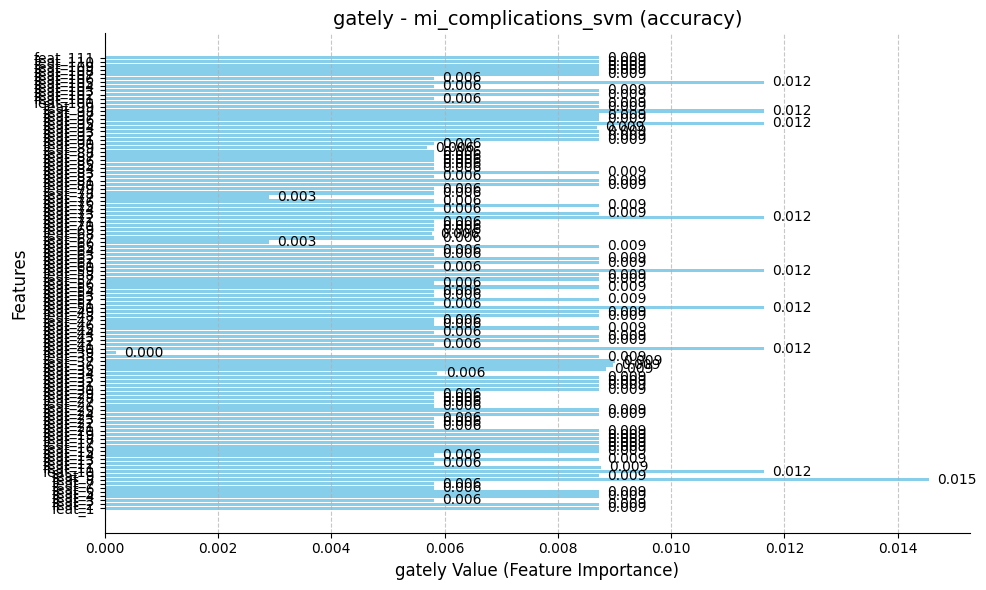

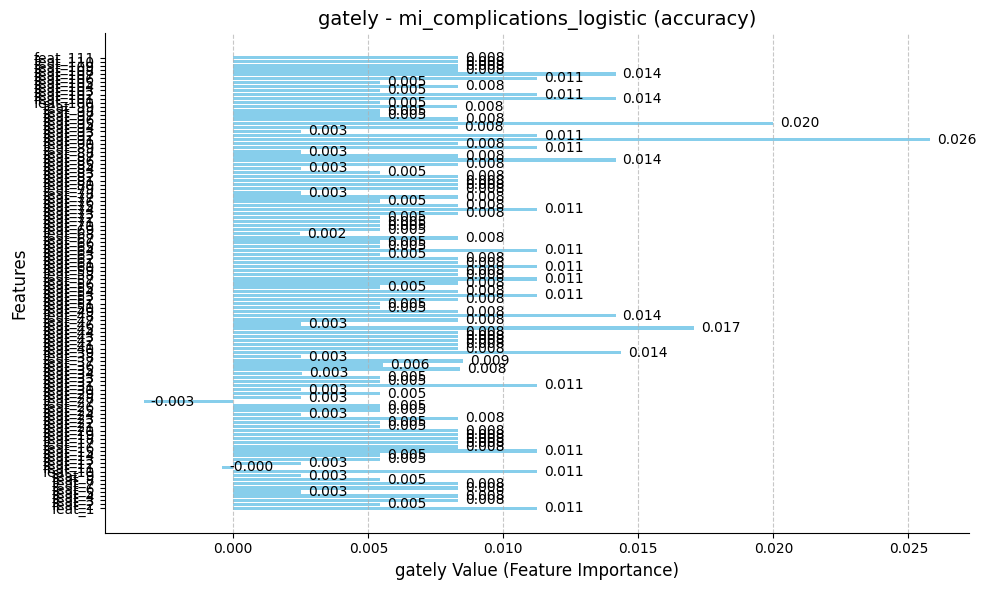

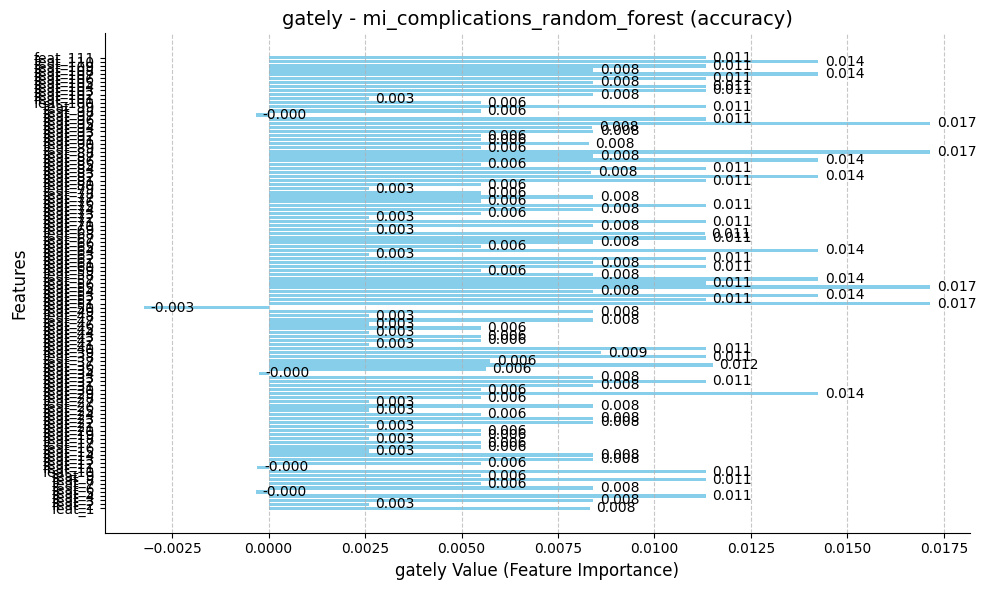

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys
import inspect

# find the repository root
HERE = Path.cwd().resolve()
root = None
for p in [HERE] + list(HERE.parents):
    if (p / "cgt_xai").is_dir():
        root = p
        break
if root is None:
    raise RuntimeError(
        f"Could not find project root from {HERE}. "
        f"Run it from inside the repository."
    )
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
print("Project root added:", root)

from scipy.stats import spearmanr, pearsonr
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, mean_squared_error,
    r2_score, mean_absolute_error
)

# Attribution methods
from cgt_xai.concepts.gately_point import exact_gately_value
from cgt_xai.concepts.shapley import montecarlo_shapley_value
from cgt_xai.concepts.least_core import montecarlo_least_core

from cgt_xai.models import get_model
from cgt_xai.utils.plotting import plot_single_valuation

# Logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config
DATASETS = ["mi_complications"]  # add "lung_cancer" if needed
MODEL_NAMES = ["svm", "logistic", "random_forest"]  # must match get_model()
SCORING = "accuracy"
RANDOM_STATE = 42

# MC settings for Shapley/Least-core
MC_ITERATIONS = 500

BASE_OUTPUT_DIR = Path("./output/feature_valuation_uci")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset loaders
def load_lung_cancer():
    path = "../../../datasets/lung-cancer.data"
    df = pd.read_csv(path, header=None, na_values="?")

    y = df.iloc[:, 0].astype(int).values
    X_df = df.iloc[:, 1:]
    feature_names = [f"attr_{i}" for i in range(1, X_df.shape[1] + 1)]

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_mi_complications(binary_let_is=True):
    path = "../../../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    let_is = df.iloc[:, 123].astype(int).values
    y = (let_is != 0).astype(int) if binary_let_is else let_is

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "lung_cancer":
        return load_lung_cancer()
    elif name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    else:
        raise ValueError(f"Unknown dataset name: {name}")

# Utility + scorer
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)

    def __iter__(self):
        return iter(self.indices)


class Utility:
    """v(S): train model on subset S, evaluate on test."""
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer,
                 feature_names=None, random_state=42):
        self.X_train = np.asarray(X_train)
        self.y_train = np.asarray(y_train)
        self.X_test = np.asarray(X_test)
        self.y_test = np.asarray(y_test)
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(self.X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]

        if len(key) == 0:
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = float(score)
            return float(score)

        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = float(score)
        return float(score)


def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")

# Attribution wrappers (Gately / MC Shapley / Least-Core MC)
_SHAPLEY_SIG = inspect.signature(montecarlo_shapley_value)
_LEASTCORE_SIG = inspect.signature(montecarlo_least_core)

def gately_attribution(utility: Utility) -> np.ndarray:
    res = exact_gately_value(utility, options=None, progress=False)
    return np.asarray(res.values, dtype=float)

def mc_shapley_attribution(utility: Utility, n_iterations: int = 500) -> np.ndarray:
    np.random.seed(utility.random_state)
    sig = _SHAPLEY_SIG
    try:
        if "random_state" in sig.parameters:
            res = montecarlo_shapley_value(
                utility, n_iterations=n_iterations,
                random_state=utility.random_state,
                progress=False
            )
        else:
            res = montecarlo_shapley_value(
                utility, n_iterations=n_iterations,
                options={"random_state": utility.random_state},
                progress=False
            )
    except (TypeError, KeyError):
        res = montecarlo_shapley_value(
            utility, n_iterations=n_iterations, options=None, progress=False
        )
    return np.asarray(res.values, dtype=float)

def least_core_attribution(utility: Utility, n_iterations: int = 500) -> np.ndarray:
    """
    Least-core MC can fail with SCS on some sampled constraint sets.
    We don't change gt_concepts/least_core.py, but we:
      - try SCS with strict options,
      - if it fails: retry with milder options,
      - if still fails: raise to outer try/except and record NaNs.
    """
    np.random.seed(utility.random_state)
    sig = _LEASTCORE_SIG

    try:
        if "random_state" in sig.parameters:
            res = montecarlo_least_core(
                utility,
                n_iterations=n_iterations,
                epsilon=1e-6,
                random_state=utility.random_state,
                options={"solver": "SCS", "max_iters": 25000, "eps": 1e-6, "verbose": False},
                progress=False
            )
        else:
            res = montecarlo_least_core(
                utility,
                n_iterations=n_iterations,
                epsilon=1e-6,
                options={"solver": "SCS", "max_iters": 25000, "eps": 1e-6, "verbose": False,
                         "random_state": utility.random_state},
                progress=False
            )
        return np.asarray(res.values, dtype=float)
    except Exception as e1:
        logger.warning(f"[least_core_mc] SCS attempt-1 failed: {type(e1).__name__}: {e1}")

    # Attempt 2: milder SCS settings (often avoids "Error parsing inputs")
    try:
        # Keep it simple and reduce constraints difficulty.
        if "random_state" in sig.parameters:
            res = montecarlo_least_core(
                utility,
                n_iterations=max(50, n_iterations // 2),
                epsilon=1e-5,
                random_state=utility.random_state,
                options={"solver": "SCS", "max_iters": 50000, "eps": 1e-4, "verbose": False},
                progress=False
            )
        else:
            res = montecarlo_least_core(
                utility,
                n_iterations=max(50, n_iterations // 2),
                epsilon=1e-5,
                options={"solver": "SCS", "max_iters": 50000, "eps": 1e-4, "verbose": False,
                         "random_state": utility.random_state},
                progress=False
            )
        return np.asarray(res.values, dtype=float)
    except Exception as e2:
        logger.warning(f"[least_core_mc] SCS attempt-2 failed: {type(e2).__name__}: {e2}")
        raise

# 4 Metrics: MC, ROAD, IROF(sufficiency), RRS
#   - np.trapz -> np.trapezoid
#   - IROF curve_norm clipped to [0,1]
#   - ROAD uses *mild* OOD by default (permute only a fraction of columns)
def _predict_continuous(model, X):
    if hasattr(model, "predict_proba"):
        proba = np.asarray(model.predict_proba(X))
        if proba.ndim == 2 and proba.shape[1] >= 2:
            return proba[:, 1].astype(float)
        return proba.reshape(-1).astype(float)
    if hasattr(model, "decision_function"):
        z = model.decision_function(X)
        return np.asarray(z).reshape(-1).astype(float)
    return np.asarray(model.predict(X)).reshape(-1).astype(float)

def _baseline_fill_values(X_train):
    return np.mean(X_train, axis=0)

def _replace_feature_with_baseline(X, j, baseline_vals):
    Xr = X.copy()
    Xr[:, j] = baseline_vals[j]
    return Xr

def _make_ood(X_ref, rng, frac=0.1):
    """
    Mild OOD: permute only a fraction of columns.
    Full-column permutation is often too destructive and makes ROAD noisy.
    """
    X_ood = X_ref.copy()
    p = X_ood.shape[1]
    k = max(1, int(frac * p))
    cols = rng.choice(p, size=k, replace=False)
    for j in cols:
        X_ood[:, j] = rng.permutation(X_ood[:, j])
    return X_ood

def metric_MC(phi_vec, model, X_test, baseline_vals):
    pred_full = _predict_continuous(model, X_test)
    deltas = np.zeros(X_test.shape[1], dtype=float)
    for j in range(X_test.shape[1]):
        X_minus = _replace_feature_with_baseline(X_test, j, baseline_vals)
        pred_minus = _predict_continuous(model, X_minus)
        deltas[j] = float(np.mean(np.abs(pred_full - pred_minus)))
    if np.std(deltas) <= 1e-12:
        return {"MC_pearson": np.nan, "MC_p": np.nan, "MC_note": "zero_variance", "MC_vector": deltas}
    r, p = pearsonr(np.abs(phi_vec), deltas)
    return {"MC_pearson": float(r), "MC_p": float(p), "MC_note": "ok", "MC_vector": deltas}

def metric_ROAD(phi_vec, model, X_test, baseline_vals, seed=42, ood_frac=0.25):
    rng = np.random.default_rng(seed)
    X_ood = _make_ood(X_test, rng, frac=ood_frac)
    fX = _predict_continuous(model, X_test)
    fX_ood = _predict_continuous(model, X_ood)
    road = np.zeros(X_test.shape[1], dtype=float)
    for j in range(X_test.shape[1]):
        X_minus = _replace_feature_with_baseline(X_test, j, baseline_vals)
        X_ood_minus = _replace_feature_with_baseline(X_ood, j, baseline_vals)
        fX_minus = _predict_continuous(model, X_minus)
        fX_ood_minus = _predict_continuous(model, X_ood_minus)
        in_eff = float(np.mean(np.abs(fX - fX_minus)))
        ood_eff = float(np.mean(np.abs(fX_ood - fX_ood_minus)))
        road[j] = in_eff - ood_eff
    if np.std(road) <= 1e-12:
        return {"ROAD_pearson": np.nan, "ROAD_p": np.nan, "ROAD_note": "degenerate_road", "ROAD_vector": road}
    r, p = pearsonr(np.abs(phi_vec), road)
    return {"ROAD_pearson": float(r), "ROAD_p": float(p), "ROAD_note": "ok", "ROAD_vector": road}

def metric_IROF_sufficiency(utility, phi_vec, max_steps=None):
    n = len(phi_vec)
    if max_steps is None:
        max_steps = n
    order = np.argsort(-np.abs(phi_vec))
    steps = min(max_steps, n)

    v0 = float(utility([]))
    v_full = float(utility(list(range(n))))

    curve = [v0]
    S = set()
    for t in range(steps):
        S.add(int(order[t]))
        curve.append(float(utility(list(S))))
    curve = np.asarray(curve, dtype=float)

    denom = (v_full - v0)
    if abs(denom) > 1e-12:
        curve_norm = (curve - v0) / abs(denom)
    else:
        curve_norm = np.zeros_like(curve)

    curve_norm = np.clip(curve_norm, 0.0, 1.0)

    x = np.arange(curve_norm.size, dtype=float)
    auc_denom = max(1, curve_norm.size - 1)
    auc = float(np.trapezoid(curve_norm, x) / auc_denom)

    k = max(1, int(0.1 * n))
    perf_10pct = float(curve[min(k, len(curve) - 1)])

    return {
        "IROF_auc_norm": auc,
        "IROF_perf_10pct": perf_10pct,
        "IROF_steps": int(steps),
        "IROF_v0": v0,
        "IROF_vfull": v_full,
        "IROF_curve": curve,
        "IROF_curve_norm": curve_norm,
    }

def _repr(model, X):
    if hasattr(model, "decision_function"):
        z = np.asarray(model.decision_function(X))
        return z.reshape(z.shape[0], -1).astype(float)
    if hasattr(model, "apply"):
        a = np.asarray(model.apply(X))
        return a.reshape(a.shape[0], -1).astype(float)
    if hasattr(model, "predict_proba"):
        p = np.asarray(model.predict_proba(X))
        return p.reshape(p.shape[0], -1).astype(float)
    y = model.predict(X)
    return np.asarray(y).reshape(-1, 1).astype(float)

def metric_RRS(phi_vec, model, X_test, baseline_vals):
    H_full = _repr(model, X_test)
    deltas = np.zeros(X_test.shape[1], dtype=float)
    for j in range(X_test.shape[1]):
        X_minus = _replace_feature_with_baseline(X_test, j, baseline_vals)
        H_minus = _repr(model, X_minus)
        diff = H_full - H_minus
        deltas[j] = float(np.mean(np.linalg.norm(diff, axis=1)))
    if np.std(deltas) <= 1e-12:
        return {"RRS_pearson": np.nan, "RRS_p": np.nan, "RRS_note": "degenerate_rrs", "RRS_vector": deltas}
    r, p = pearsonr(np.abs(phi_vec), deltas)
    return {"RRS_pearson": float(r), "RRS_p": float(p), "RRS_note": "ok", "RRS_vector": deltas}

def compute_4_metrics(phi_vec, trained_model, utility_obj, X_train, X_test, seed=42):
    baseline_vals = _baseline_fill_values(X_train)
    out = {}
    out.update(metric_MC(phi_vec, trained_model, X_test, baseline_vals))
    out.update(metric_ROAD(phi_vec, trained_model, X_test, baseline_vals, seed=seed + 777, ood_frac=0.25))
    out.update(metric_IROF_sufficiency(utility_obj, phi_vec))
    out.update(metric_RRS(phi_vec, trained_model, X_test, baseline_vals))
    return out

# Main
def main():
    scorer = get_scorer(SCORING)

    attribution_methods = {
        "gately": ("exact", gately_attribution)
    }

    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)
        n_features = X_train.shape[1]
        all_features_set = set(range(n_features))

        for model_name in MODEL_NAMES:
            logger.info("\n" + "=" * 70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("=" * 70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            # Train one "full" model for MC/ROAD/RRS
            trained_model = get_model(model_name, RANDOM_STATE)
            trained_model.fit(X_train, y_train)

            # Utility for subset retraining v(S)
            utility = Utility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            v_N = utility(list(all_features_set))
            logger.info(f"  v(N) with all features ({SCORING}) = {v_N:.4f}")

            results = {}
            summary_rows = []

            for method_name, (kind, attrib_fn) in attribution_methods.items():
                logger.info("\n" + "-" * 70)
                logger.info(f"Attribution method: {method_name}")
                logger.info("-" * 70)

                # Compute attribution with failure isolation (esp. least-core)
                phi = None
                err_msg = ""
                try:
                    if kind == "mc":
                        phi = attrib_fn(utility, n_iterations=MC_ITERATIONS)
                    else:
                        phi = attrib_fn(utility)
                    phi = np.asarray(phi, dtype=float)
                    results[method_name] = phi
                except Exception as e:
                    err_msg = f"{type(e).__name__}: {e}"
                    logger.warning(f"  Error: Attribution failed for {method_name}: {err_msg}")
                    phi = np.full(n_features, np.nan, dtype=float)
                    results[method_name] = phi

                # Save valuations even if NaNs (debugging convenience)
                df_vals = pd.DataFrame({"method": method_name, "feature": feature_names, "value": phi})
                vals_csv_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_{method_name}.csv"
                df_vals.to_csv(vals_csv_path, index=False)
                logger.info(f"  Saved valuations to: {vals_csv_path}")

                if np.isfinite(phi).any():
                    try:
                        plot_single_valuation(
                            phi, feature_names,
                            method_name=method_name,
                            title=f"{method_name} - {dataset_name}_{model_name} ({SCORING})",
                            output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_{method_name}.png"
                        )
                    except Exception as e:
                        logger.warning(f"  Could not plot {method_name}: {e}")

                # If attribution failed, write a summary row with NaNs
                if not np.isfinite(phi).all():
                    summary_rows.append({
                        "dataset": dataset_name,
                        "model": model_name,
                        "method": method_name,
                        "attribution_error": err_msg,

                        "MC_pearson": np.nan, "MC_p": np.nan,
                        "ROAD_pearson": np.nan, "ROAD_p": np.nan,
                        "IROF_auc_norm": np.nan, "IROF_perf_10pct": np.nan,
                        "IROF_v0": np.nan, "IROF_vfull": np.nan,
                        "RRS_pearson": np.nan, "RRS_p": np.nan,
                    })
                    continue

                # Compute 4 metrics
                m = compute_4_metrics(phi, trained_model, utility, X_train, X_test, seed=RANDOM_STATE)

                # Save per-feature vectors
                per_feat_df = pd.DataFrame({
                    "feature": feature_names,
                    "phi": phi,
                    "MC_delta_pred_i": m.get("MC_vector", np.full(n_features, np.nan)),
                    "ROAD_i": m.get("ROAD_vector", np.full(n_features, np.nan)),
                    "RRS_i": m.get("RRS_vector", np.full(n_features, np.nan)),
                })
                per_feat_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_per_feature_MC_ROAD_RRS_{method_name}.csv"
                per_feat_df.to_csv(per_feat_csv, index=False)
                logger.info(f"  Saved per-feature MC/ROAD/RRS to: {per_feat_csv}")

                # Save IROF curve
                irof_curve_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_IROF_curve_{method_name}.csv"
                pd.DataFrame({
                    "k_added": np.arange(len(m["IROF_curve"])),
                    "score": m["IROF_curve"],
                    "score_norm": m["IROF_curve_norm"],
                }).to_csv(irof_curve_csv, index=False)

                summary_rows.append({
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": method_name,
                    "attribution_error": "",

                    "MC_pearson": m["MC_pearson"],
                    "MC_p": m["MC_p"],
                    "MC_note": m["MC_note"],

                    "ROAD_pearson": m["ROAD_pearson"],
                    "ROAD_p": m["ROAD_p"],
                    "ROAD_note": m["ROAD_note"],

                    "IROF_auc_norm": m["IROF_auc_norm"],
                    "IROF_perf_10pct": m["IROF_perf_10pct"],
                    "IROF_v0": m["IROF_v0"],
                    "IROF_vfull": m["IROF_vfull"],

                    "RRS_pearson": m["RRS_pearson"],
                    "RRS_p": m["RRS_p"],
                    "RRS_note": m["RRS_note"],
                })

                logger.info(
                    f"  Metrics({method_name}): "
                    f"MC r={m['MC_pearson']:.4f}, ROAD r={m['ROAD_pearson']:.4f}, "
                    f"IROF AUC={m['IROF_auc_norm']:.4f}, RRS r={m['RRS_pearson']:.4f}"
                )

            logger.info("\nCalculating Global Sensitivity (Leave-One-Out Impact)...")
            global_impacts = []
            for i in range(n_features):
                v_N_minus_i = utility(list(all_features_set - {i}))
                global_impacts.append(v_N - v_N_minus_i)
            global_impact_vector = np.asarray(global_impacts, dtype=float)

            sens_rows = []
            for method_name, phi in results.items():
                if not np.isfinite(phi).all():
                    sens_rows.append({
                        "method": method_name,
                        "sensitivity_spearman_absphi": np.nan,
                        "p_value_spearman_absphi": np.nan,
                        "sensitivity_pearson_absphi": np.nan,
                        "p_value_pearson_absphi": np.nan,
                        "cosine_similarity_abs": np.nan,
                    })
                    continue

                # Use |phi| for faithfulness-alignment style metrics
                corr_spearman, p_spearman = spearmanr(np.abs(phi), global_impact_vector)
                corr_pearson, p_pearson = pearsonr(np.abs(phi), global_impact_vector)

                phi_abs = np.abs(phi)
                imp_abs = np.abs(global_impact_vector)
                cos_sim = float(np.dot(phi_abs, imp_abs) / (
                    (np.linalg.norm(phi_abs) * np.linalg.norm(imp_abs)) + 1e-10
                ))

                sens_rows.append({
                    "method": method_name,
                    "sensitivity_spearman_absphi": corr_spearman,
                    "p_value_spearman_absphi": p_spearman,
                    "sensitivity_pearson_absphi": corr_pearson,
                    "p_value_pearson_absphi": p_pearson,
                    "cosine_similarity_abs": cos_sim
                })

                logger.info(
                    f"  {method_name}: "
                    f"Spearman(|phi|,LOO)={corr_spearman:.4f}, "
                    f"Pearson(|phi|,LOO)={corr_pearson:.4f}, "
                    f"AbsCos={cos_sim:.4f}"
                )

            sensitivity_df = pd.DataFrame(sens_rows)
            sens_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_sensitivity_all_methods.csv"
            sensitivity_df.to_csv(sens_csv, index=False)
            logger.info(f"  Saved global sensitivity to: {sens_csv}")

            logger.info("\nEvaluating robustness under input noise...")
            noise_level = 0.05
            noise = np.random.normal(0, noise_level * X_train.std(axis=0), X_train.shape)
            X_train_noisy = X_train + noise

            utility_noisy = Utility(
                X_train_noisy, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            robustness_rows = []
            for method_name, (kind, attrib_fn) in attribution_methods.items():
                phi_original = results[method_name]
                if not np.isfinite(phi_original).all():
                    robustness_rows.append({
                        "method": method_name,
                        "cosine_similarity_abs": np.nan,
                        "rank_correlation": np.nan,
                        "normalized_l2_distance": np.nan
                    })
                    continue

                try:
                    if kind == "mc":
                        phi_noisy = attrib_fn(utility_noisy, n_iterations=MC_ITERATIONS)
                    else:
                        phi_noisy = attrib_fn(utility_noisy)
                    phi_noisy = np.asarray(phi_noisy, dtype=float)
                except Exception as e:
                    logger.warning(f"  Error: Robustness attribution failed for {method_name}: {type(e).__name__}: {e}")
                    robustness_rows.append({
                        "method": method_name,
                        "cosine_similarity_abs": np.nan,
                        "rank_correlation": np.nan,
                        "normalized_l2_distance": np.nan
                    })
                    continue

                # Robustness: magnitude cosine
                o_abs = np.abs(phi_original)
                n_abs = np.abs(phi_noisy)
                cos_sim = float(np.dot(o_abs, n_abs) / (
                    (np.linalg.norm(o_abs) * np.linalg.norm(n_abs)) + 1e-10
                ))

                l2_dist = np.linalg.norm(phi_original - phi_noisy)
                l2_norm = l2_dist / (np.linalg.norm(phi_original) + 1e-10)
                rank_corr, _ = spearmanr(phi_original, phi_noisy)

                robustness_rows.append({
                    "method": method_name,
                    "cosine_similarity_abs": cos_sim,
                    "rank_correlation": rank_corr,
                    "normalized_l2_distance": l2_norm
                })

                logger.info(
                    f"  {method_name}: AbsCos={cos_sim:.4f}, "
                    f"RankCorr={rank_corr:.4f}, L2={l2_norm:.4f}"
                )

            robustness_df = pd.DataFrame(robustness_rows)
            rob_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_robustness_all_methods.csv"
            robustness_df.to_csv(rob_csv, index=False)
            logger.info(f"  Saved global robustness to: {rob_csv}")

            summary_df = pd.DataFrame(summary_rows)
            metrics_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_MC_ROAD_IROF_RRS_summary.csv"
            summary_df.to_csv(metrics_csv, index=False)
            logger.info(f"  Saved 4-metric summary to: {metrics_csv}")

            fig, axes = plt.subplots(1, 3, figsize=(18, 6))

            ax1 = axes[0]
            ax1.barh(sensitivity_df["method"], sensitivity_df["sensitivity_spearman_absphi"])
            ax1.set_xlabel("Spearman(|phi|, LOO)")
            ax1.set_title("Global Sensitivity\n(|Attribution| ↔ LOO Impact)")
            ax1.axvline(0, color="red", linestyle="--", linewidth=1)
            ax1.grid(axis="x", alpha=0.3)

            ax2 = axes[1]
            ax2.barh(sensitivity_df["method"], sensitivity_df["cosine_similarity_abs"])
            ax2.set_xlabel("Abs Cosine Similarity")
            ax2.set_title("Magnitude Alignment\n(|phi| vs |LOO|)")
            ax2.axvline(1.0, color="green", linestyle="--", linewidth=1)
            ax2.grid(axis="x", alpha=0.3)

            ax3 = axes[2]
            ax3.barh(robustness_df["method"], robustness_df["cosine_similarity_abs"])
            ax3.set_xlabel("Abs Cosine (Original ↔ Noisy)")
            ax3.set_title("Global Robustness\n(Magnitude Stability)")
            ax3.axvline(1.0, color="green", linestyle="--", linewidth=1)
            ax3.grid(axis="x", alpha=0.3)

            plt.tight_layout()
            fig_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_faithfulness_all_methods.png"
            plt.savefig(fig_path, dpi=300, bbox_inches="tight")
            plt.close(fig)

            logger.info(f"\nAll results saved to: {OUTPUT_DIR}")
            logger.info("=" * 70)

if __name__ == "__main__":
    main()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys
import inspect

# find the repository root
HERE = Path.cwd().resolve()
root = None
for p in [HERE] + list(HERE.parents):
    if (p / "cgt_xai").is_dir():
        root = p
        break
if root is None:
    raise RuntimeError(
        f"Could not find project root from {HERE}. "
        f"Run it from inside the repository."
    )
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
print("Project root added:", root)

from scipy.stats import spearmanr, pearsonr
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, mean_squared_error,
    r2_score, mean_absolute_error
)

# Attribution methods
from cgt_xai.concepts.gately_point import exact_gately_value
from cgt_xai.concepts.shapley import montecarlo_shapley_value
from cgt_xai.concepts.least_core import montecarlo_least_core

from cgt_xai.models import get_model
from cgt_xai.utils.plotting import plot_single_valuation

# Logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config
DATASETS = ["mi_complications"]  # add "lung_cancer" if needed
MODEL_NAMES = [ "logistic", "random_forest"]  # must match get_model()
SCORING = "accuracy"
RANDOM_STATE = 42

# MC settings for Shapley/Least-core
MC_ITERATIONS = 500

BASE_OUTPUT_DIR = Path("./output/feature_valuation_uci")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset loaders
def load_lung_cancer():
    path = "../../../datasets/lung-cancer.data"
    df = pd.read_csv(path, header=None, na_values="?")

    y = df.iloc[:, 0].astype(int).values
    X_df = df.iloc[:, 1:]
    feature_names = [f"attr_{i}" for i in range(1, X_df.shape[1] + 1)]

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_mi_complications(binary_let_is=True):
    path = "../../../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    let_is = df.iloc[:, 123].astype(int).values
    y = (let_is != 0).astype(int) if binary_let_is else let_is

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "lung_cancer":
        return load_lung_cancer()
    elif name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    else:
        raise ValueError(f"Unknown dataset name: {name}")

# Utility + scorer
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)

    def __iter__(self):
        return iter(self.indices)


class Utility:
    """v(S): train model on subset S, evaluate on test."""
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer,
                 feature_names=None, random_state=42):
        self.X_train = np.asarray(X_train)
        self.y_train = np.asarray(y_train)
        self.X_test = np.asarray(X_test)
        self.y_test = np.asarray(y_test)
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(self.X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]

        if len(key) == 0:
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = float(score)
            return float(score)

        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = float(score)
        return float(score)


def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")

# Attribution wrappers (Gately / MC Shapley / Least-Core MC)
_SHAPLEY_SIG = inspect.signature(montecarlo_shapley_value)
_LEASTCORE_SIG = inspect.signature(montecarlo_least_core)

def gately_attribution(utility: Utility) -> np.ndarray:
    res = exact_gately_value(utility, options=None, progress=False)
    return np.asarray(res.values, dtype=float)

def mc_shapley_attribution(utility: Utility, n_iterations: int = 500) -> np.ndarray:
    np.random.seed(utility.random_state)
    sig = _SHAPLEY_SIG
    try:
        if "random_state" in sig.parameters:
            res = montecarlo_shapley_value(
                utility, n_iterations=n_iterations,
                random_state=utility.random_state,
                progress=False
            )
        else:
            res = montecarlo_shapley_value(
                utility, n_iterations=n_iterations,
                options={"random_state": utility.random_state},
                progress=False
            )
    except (TypeError, KeyError):
        res = montecarlo_shapley_value(
            utility, n_iterations=n_iterations, options=None, progress=False
        )
    return np.asarray(res.values, dtype=float)

def least_core_attribution(utility: Utility, n_iterations: int = 500) -> np.ndarray:
    """
    Least-core MC can fail with SCS on some sampled constraint sets.
    We don't change gt_concepts/least_core.py, but we:
      - try SCS with strict options,
      - if it fails: retry with milder options,
      - if still fails: raise to outer try/except and record NaNs.
    """
    np.random.seed(utility.random_state)
    sig = _LEASTCORE_SIG

    try:
        if "random_state" in sig.parameters:
            res = montecarlo_least_core(
                utility,
                n_iterations=n_iterations,
                epsilon=1e-6,
                random_state=utility.random_state,
                options={"solver": "SCS", "max_iters": 25000, "eps": 1e-6, "verbose": False},
                progress=False
            )
        else:
            res = montecarlo_least_core(
                utility,
                n_iterations=n_iterations,
                epsilon=1e-6,
                options={"solver": "SCS", "max_iters": 25000, "eps": 1e-6, "verbose": False,
                         "random_state": utility.random_state},
                progress=False
            )
        return np.asarray(res.values, dtype=float)
    except Exception as e1:
        logger.warning(f"[least_core_mc] SCS attempt-1 failed: {type(e1).__name__}: {e1}")

    # Attempt 2: milder SCS settings (often avoids "Error parsing inputs")
    try:
        # Keep it simple and reduce constraints difficulty.
        if "random_state" in sig.parameters:
            res = montecarlo_least_core(
                utility,
                n_iterations=max(50, n_iterations // 2),
                epsilon=1e-5,
                random_state=utility.random_state,
                options={"solver": "SCS", "max_iters": 50000, "eps": 1e-4, "verbose": False},
                progress=False
            )
        else:
            res = montecarlo_least_core(
                utility,
                n_iterations=max(50, n_iterations // 2),
                epsilon=1e-5,
                options={"solver": "SCS", "max_iters": 50000, "eps": 1e-4, "verbose": False,
                         "random_state": utility.random_state},
                progress=False
            )
        return np.asarray(res.values, dtype=float)
    except Exception as e2:
        logger.warning(f"[least_core_mc] SCS attempt-2 failed: {type(e2).__name__}: {e2}")
        raise

# 4 Metrics: MC, ROAD, IROF(sufficiency), RRS
#   - np.trapz -> np.trapezoid
#   - IROF curve_norm clipped to [0,1]
#   - ROAD uses *mild* OOD by default (permute only a fraction of columns)
def _predict_continuous(model, X):
    if hasattr(model, "predict_proba"):
        proba = np.asarray(model.predict_proba(X))
        if proba.ndim == 2 and proba.shape[1] >= 2:
            return proba[:, 1].astype(float)
        return proba.reshape(-1).astype(float)
    if hasattr(model, "decision_function"):
        z = model.decision_function(X)
        return np.asarray(z).reshape(-1).astype(float)
    return np.asarray(model.predict(X)).reshape(-1).astype(float)

def _baseline_fill_values(X_train):
    return np.mean(X_train, axis=0)

def _replace_feature_with_baseline(X, j, baseline_vals):
    Xr = X.copy()
    Xr[:, j] = baseline_vals[j]
    return Xr

def _make_ood(X_ref, rng, frac=0.25):
    """
    Mild OOD: permute only a fraction of columns.
    Full-column permutation is often too destructive and makes ROAD noisy.
    """
    X_ood = X_ref.copy()
    p = X_ood.shape[1]
    k = max(1, int(frac * p))
    cols = rng.choice(p, size=k, replace=False)
    for j in cols:
        X_ood[:, j] = rng.permutation(X_ood[:, j])
    return X_ood

def metric_MC(phi_vec, model, X_test, baseline_vals):
    pred_full = _predict_continuous(model, X_test)
    deltas = np.zeros(X_test.shape[1], dtype=float)
    for j in range(X_test.shape[1]):
        X_minus = _replace_feature_with_baseline(X_test, j, baseline_vals)
        pred_minus = _predict_continuous(model, X_minus)
        deltas[j] = float(np.mean(np.abs(pred_full - pred_minus)))
    if np.std(deltas) <= 1e-12:
        return {"MC_pearson": np.nan, "MC_p": np.nan, "MC_note": "zero_variance", "MC_vector": deltas}
    r, p = pearsonr(np.abs(phi_vec), deltas)
    return {"MC_pearson": float(r), "MC_p": float(p), "MC_note": "ok", "MC_vector": deltas}

def metric_ROAD(phi_vec, model, X_test, baseline_vals, seed=42, ood_frac=0.25):
    rng = np.random.default_rng(seed)
    X_ood = _make_ood(X_test, rng, frac=ood_frac)
    fX = _predict_continuous(model, X_test)
    fX_ood = _predict_continuous(model, X_ood)
    road = np.zeros(X_test.shape[1], dtype=float)
    for j in range(X_test.shape[1]):
        X_minus = _replace_feature_with_baseline(X_test, j, baseline_vals)
        X_ood_minus = _replace_feature_with_baseline(X_ood, j, baseline_vals)
        fX_minus = _predict_continuous(model, X_minus)
        fX_ood_minus = _predict_continuous(model, X_ood_minus)
        in_eff = float(np.mean(np.abs(fX - fX_minus)))
        ood_eff = float(np.mean(np.abs(fX_ood - fX_ood_minus)))
        road[j] = in_eff - ood_eff
    if np.std(road) <= 1e-12:
        return {"ROAD_pearson": np.nan, "ROAD_p": np.nan, "ROAD_note": "degenerate_road", "ROAD_vector": road}
    r, p = pearsonr(np.abs(phi_vec), road)
    return {"ROAD_pearson": float(r), "ROAD_p": float(p), "ROAD_note": "ok", "ROAD_vector": road}

def metric_IROF_sufficiency(utility, phi_vec, max_steps=None):
    n = len(phi_vec)
    if max_steps is None:
        max_steps = n
    order = np.argsort(-np.abs(phi_vec))
    steps = min(max_steps, n)

    v0 = float(utility([]))
    v_full = float(utility(list(range(n))))

    curve = [v0]
    S = set()
    for t in range(steps):
        S.add(int(order[t]))
        curve.append(float(utility(list(S))))
    curve = np.asarray(curve, dtype=float)

    denom = (v_full - v0)
    if abs(denom) > 1e-12:
        curve_norm = (curve - v0) / abs(denom)
    else:
        curve_norm = np.zeros_like(curve)

    curve_norm = np.clip(curve_norm, 0.0, 1.0)

    x = np.arange(curve_norm.size, dtype=float)
    auc_denom = max(1, curve_norm.size - 1)
    auc = float(np.trapezoid(curve_norm, x) / auc_denom)

    k = max(1, int(0.1 * n))
    perf_10pct = float(curve[min(k, len(curve) - 1)])

    return {
        "IROF_auc_norm": auc,
        "IROF_perf_10pct": perf_10pct,
        "IROF_steps": int(steps),
        "IROF_v0": v0,
        "IROF_vfull": v_full,
        "IROF_curve": curve,
        "IROF_curve_norm": curve_norm,
    }

def _repr(model, X):
    if hasattr(model, "decision_function"):
        z = np.asarray(model.decision_function(X))
        return z.reshape(z.shape[0], -1).astype(float)
    if hasattr(model, "apply"):
        a = np.asarray(model.apply(X))
        return a.reshape(a.shape[0], -1).astype(float)
    if hasattr(model, "predict_proba"):
        p = np.asarray(model.predict_proba(X))
        return p.reshape(p.shape[0], -1).astype(float)
    y = model.predict(X)
    return np.asarray(y).reshape(-1, 1).astype(float)

def metric_RRS(phi_vec, model, X_test, baseline_vals):
    H_full = _repr(model, X_test)
    deltas = np.zeros(X_test.shape[1], dtype=float)
    for j in range(X_test.shape[1]):
        X_minus = _replace_feature_with_baseline(X_test, j, baseline_vals)
        H_minus = _repr(model, X_minus)
        diff = H_full - H_minus
        deltas[j] = float(np.mean(np.linalg.norm(diff, axis=1)))
    if np.std(deltas) <= 1e-12:
        return {"RRS_pearson": np.nan, "RRS_p": np.nan, "RRS_note": "degenerate_rrs", "RRS_vector": deltas}
    r, p = pearsonr(np.abs(phi_vec), deltas)
    return {"RRS_pearson": float(r), "RRS_p": float(p), "RRS_note": "ok", "RRS_vector": deltas}

def compute_4_metrics(phi_vec, trained_model, utility_obj, X_train, X_test, seed=42):
    baseline_vals = _baseline_fill_values(X_train)
    out = {}
    out.update(metric_MC(phi_vec, trained_model, X_test, baseline_vals))
    out.update(metric_ROAD(phi_vec, trained_model, X_test, baseline_vals, seed=seed + 777, ood_frac=0.25))
    out.update(metric_IROF_sufficiency(utility_obj, phi_vec))
    out.update(metric_RRS(phi_vec, trained_model, X_test, baseline_vals))
    return out

# Main
def main():
    scorer = get_scorer(SCORING)

    attribution_methods = {
          "mc_shapley": ("mc", mc_shapley_attribution)
    }

    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)
        n_features = X_train.shape[1]
        all_features_set = set(range(n_features))

        for model_name in MODEL_NAMES:
            logger.info("\n" + "=" * 70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("=" * 70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            # Train one "full" model for MC/ROAD/RRS
            trained_model = get_model(model_name, RANDOM_STATE)
            trained_model.fit(X_train, y_train)

            # Utility for subset retraining v(S)
            utility = Utility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            v_N = utility(list(all_features_set))
            logger.info(f"  v(N) with all features ({SCORING}) = {v_N:.4f}")

            results = {}
            summary_rows = []

            for method_name, (kind, attrib_fn) in attribution_methods.items():
                logger.info("\n" + "-" * 70)
                logger.info(f"Attribution method: {method_name}")
                logger.info("-" * 70)

                # Compute attribution with failure isolation (esp. least-core)
                phi = None
                err_msg = ""
                try:
                    if kind == "mc":
                        phi = attrib_fn(utility, n_iterations=MC_ITERATIONS)
                    else:
                        phi = attrib_fn(utility)
                    phi = np.asarray(phi, dtype=float)
                    results[method_name] = phi
                except Exception as e:
                    err_msg = f"{type(e).__name__}: {e}"
                    logger.warning(f"  Error: Attribution failed for {method_name}: {err_msg}")
                    phi = np.full(n_features, np.nan, dtype=float)
                    results[method_name] = phi

                # Save valuations even if NaNs (debugging convenience)
                df_vals = pd.DataFrame({"method": method_name, "feature": feature_names, "value": phi})
                vals_csv_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_{method_name}.csv"
                df_vals.to_csv(vals_csv_path, index=False)
                logger.info(f"  Saved valuations to: {vals_csv_path}")

                if np.isfinite(phi).any():
                    try:
                        plot_single_valuation(
                            phi, feature_names,
                            method_name=method_name,
                            title=f"{method_name} - {dataset_name}_{model_name} ({SCORING})",
                            output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_{method_name}.png"
                        )
                    except Exception as e:
                        logger.warning(f"  Could not plot {method_name}: {e}")

                # If attribution failed, write a summary row with NaNs
                if not np.isfinite(phi).all():
                    summary_rows.append({
                        "dataset": dataset_name,
                        "model": model_name,
                        "method": method_name,
                        "attribution_error": err_msg,

                        "MC_pearson": np.nan, "MC_p": np.nan,
                        "ROAD_pearson": np.nan, "ROAD_p": np.nan,
                        "IROF_auc_norm": np.nan, "IROF_perf_10pct": np.nan,
                        "IROF_v0": np.nan, "IROF_vfull": np.nan,
                        "RRS_pearson": np.nan, "RRS_p": np.nan,
                    })
                    continue

                # Compute 4 metrics
                m = compute_4_metrics(phi, trained_model, utility, X_train, X_test, seed=RANDOM_STATE)

                # Save per-feature vectors
                per_feat_df = pd.DataFrame({
                    "feature": feature_names,
                    "phi": phi,
                    "MC_delta_pred_i": m.get("MC_vector", np.full(n_features, np.nan)),
                    "ROAD_i": m.get("ROAD_vector", np.full(n_features, np.nan)),
                    "RRS_i": m.get("RRS_vector", np.full(n_features, np.nan)),
                })
                per_feat_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_per_feature_MC_ROAD_RRS_{method_name}.csv"
                per_feat_df.to_csv(per_feat_csv, index=False)
                logger.info(f"  Saved per-feature MC/ROAD/RRS to: {per_feat_csv}")

                # Save IROF curve
                irof_curve_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_IROF_curve_{method_name}.csv"
                pd.DataFrame({
                    "k_added": np.arange(len(m["IROF_curve"])),
                    "score": m["IROF_curve"],
                    "score_norm": m["IROF_curve_norm"],
                }).to_csv(irof_curve_csv, index=False)

                summary_rows.append({
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": method_name,
                    "attribution_error": "",

                    "MC_pearson": m["MC_pearson"],
                    "MC_p": m["MC_p"],
                    "MC_note": m["MC_note"],

                    "ROAD_pearson": m["ROAD_pearson"],
                    "ROAD_p": m["ROAD_p"],
                    "ROAD_note": m["ROAD_note"],

                    "IROF_auc_norm": m["IROF_auc_norm"],
                    "IROF_perf_10pct": m["IROF_perf_10pct"],
                    "IROF_v0": m["IROF_v0"],
                    "IROF_vfull": m["IROF_vfull"],

                    "RRS_pearson": m["RRS_pearson"],
                    "RRS_p": m["RRS_p"],
                    "RRS_note": m["RRS_note"],
                })

                logger.info(
                    f"  Metrics({method_name}): "
                    f"MC r={m['MC_pearson']:.4f}, ROAD r={m['ROAD_pearson']:.4f}, "
                    f"IROF AUC={m['IROF_auc_norm']:.4f}, RRS r={m['RRS_pearson']:.4f}"
                )

            logger.info("\nCalculating Global Sensitivity (Leave-One-Out Impact)...")
            global_impacts = []
            for i in range(n_features):
                v_N_minus_i = utility(list(all_features_set - {i}))
                global_impacts.append(v_N - v_N_minus_i)
            global_impact_vector = np.asarray(global_impacts, dtype=float)

            sens_rows = []
            for method_name, phi in results.items():
                if not np.isfinite(phi).all():
                    sens_rows.append({
                        "method": method_name,
                        "sensitivity_spearman_absphi": np.nan,
                        "p_value_spearman_absphi": np.nan,
                        "sensitivity_pearson_absphi": np.nan,
                        "p_value_pearson_absphi": np.nan,
                        "cosine_similarity_abs": np.nan,
                    })
                    continue

                # Use |phi| for faithfulness-alignment style metrics
                corr_spearman, p_spearman = spearmanr(np.abs(phi), global_impact_vector)
                corr_pearson, p_pearson = pearsonr(np.abs(phi), global_impact_vector)

                phi_abs = np.abs(phi)
                imp_abs = np.abs(global_impact_vector)
                cos_sim = float(np.dot(phi_abs, imp_abs) / (
                    (np.linalg.norm(phi_abs) * np.linalg.norm(imp_abs)) + 1e-10
                ))

                sens_rows.append({
                    "method": method_name,
                    "sensitivity_spearman_absphi": corr_spearman,
                    "p_value_spearman_absphi": p_spearman,
                    "sensitivity_pearson_absphi": corr_pearson,
                    "p_value_pearson_absphi": p_pearson,
                    "cosine_similarity_abs": cos_sim
                })

                logger.info(
                    f"  {method_name}: "
                    f"Spearman(|phi|,LOO)={corr_spearman:.4f}, "
                    f"Pearson(|phi|,LOO)={corr_pearson:.4f}, "
                    f"AbsCos={cos_sim:.4f}"
                )

            sensitivity_df = pd.DataFrame(sens_rows)
            sens_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_sensitivity_all_methods.csv"
            sensitivity_df.to_csv(sens_csv, index=False)
            logger.info(f"  Saved global sensitivity to: {sens_csv}")

            logger.info("\nEvaluating robustness under input noise...")
            noise_level = 0.05
            noise = np.random.normal(0, noise_level * X_train.std(axis=0), X_train.shape)
            X_train_noisy = X_train + noise

            utility_noisy = Utility(
                X_train_noisy, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            robustness_rows = []
            for method_name, (kind, attrib_fn) in attribution_methods.items():
                phi_original = results[method_name]
                if not np.isfinite(phi_original).all():
                    robustness_rows.append({
                        "method": method_name,
                        "cosine_similarity_abs": np.nan,
                        "rank_correlation": np.nan,
                        "normalized_l2_distance": np.nan
                    })
                    continue

                try:
                    if kind == "mc":
                        phi_noisy = attrib_fn(utility_noisy, n_iterations=MC_ITERATIONS)
                    else:
                        phi_noisy = attrib_fn(utility_noisy)
                    phi_noisy = np.asarray(phi_noisy, dtype=float)
                except Exception as e:
                    logger.warning(f"  Error: Robustness attribution failed for {method_name}: {type(e).__name__}: {e}")
                    robustness_rows.append({
                        "method": method_name,
                        "cosine_similarity_abs": np.nan,
                        "rank_correlation": np.nan,
                        "normalized_l2_distance": np.nan
                    })
                    continue

                # Robustness: magnitude cosine
                o_abs = np.abs(phi_original)
                n_abs = np.abs(phi_noisy)
                cos_sim = float(np.dot(o_abs, n_abs) / (
                    (np.linalg.norm(o_abs) * np.linalg.norm(n_abs)) + 1e-10
                ))

                l2_dist = np.linalg.norm(phi_original - phi_noisy)
                l2_norm = l2_dist / (np.linalg.norm(phi_original) + 1e-10)
                rank_corr, _ = spearmanr(phi_original, phi_noisy)

                robustness_rows.append({
                    "method": method_name,
                    "cosine_similarity_abs": cos_sim,
                    "rank_correlation": rank_corr,
                    "normalized_l2_distance": l2_norm
                })

                logger.info(
                    f"  {method_name}: AbsCos={cos_sim:.4f}, "
                    f"RankCorr={rank_corr:.4f}, L2={l2_norm:.4f}"
                )

            robustness_df = pd.DataFrame(robustness_rows)
            rob_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_robustness_all_methods.csv"
            robustness_df.to_csv(rob_csv, index=False)
            logger.info(f"  Saved global robustness to: {rob_csv}")

            summary_df = pd.DataFrame(summary_rows)
            metrics_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_MC_ROAD_IROF_RRS_summary.csv"
            summary_df.to_csv(metrics_csv, index=False)
            logger.info(f"  Saved 4-metric summary to: {metrics_csv}")

            fig, axes = plt.subplots(1, 3, figsize=(18, 6))

            ax1 = axes[0]
            ax1.barh(sensitivity_df["method"], sensitivity_df["sensitivity_spearman_absphi"])
            ax1.set_xlabel("Spearman(|phi|, LOO)")
            ax1.set_title("Global Sensitivity\n(|Attribution| ↔ LOO Impact)")
            ax1.axvline(0, color="red", linestyle="--", linewidth=1)
            ax1.grid(axis="x", alpha=0.3)

            ax2 = axes[1]
            ax2.barh(sensitivity_df["method"], sensitivity_df["cosine_similarity_abs"])
            ax2.set_xlabel("Abs Cosine Similarity")
            ax2.set_title("Magnitude Alignment\n(|phi| vs |LOO|)")
            ax2.axvline(1.0, color="green", linestyle="--", linewidth=1)
            ax2.grid(axis="x", alpha=0.3)

            ax3 = axes[2]
            ax3.barh(robustness_df["method"], robustness_df["cosine_similarity_abs"])
            ax3.set_xlabel("Abs Cosine (Original ↔ Noisy)")
            ax3.set_title("Global Robustness\n(Magnitude Stability)")
            ax3.axvline(1.0, color="green", linestyle="--", linewidth=1)
            ax3.grid(axis="x", alpha=0.3)

            plt.tight_layout()
            fig_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_faithfulness_all_methods.png"
            plt.savefig(fig_path, dpi=300, bbox_inches="tight")
            plt.close(fig)

            logger.info(f"\nAll results saved to: {OUTPUT_DIR}")
            logger.info("=" * 70)

if __name__ == "__main__":
    main()

✅ Project root added: 


✅ Project root added: 


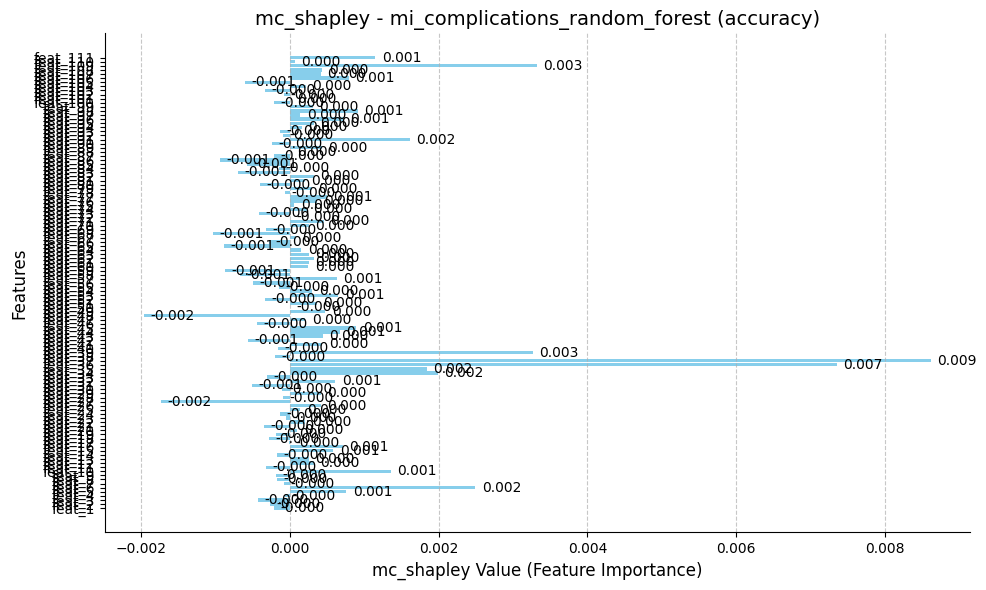

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys
import inspect

# find the repository root
HERE = Path.cwd().resolve()
root = None
for p in [HERE] + list(HERE.parents):
    if (p / "cgt_xai").is_dir():
        root = p
        break
if root is None:
    raise RuntimeError(
        f"Could not find project root from {HERE}. "
        f"Run it from inside the repository."
    )
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
print("Project root added:", root)

from scipy.stats import spearmanr, pearsonr
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, mean_squared_error,
    r2_score, mean_absolute_error
)

# Attribution methods
from cgt_xai.concepts.gately_point import exact_gately_value
from cgt_xai.concepts.shapley import montecarlo_shapley_value
from cgt_xai.concepts.least_core import montecarlo_least_core

from cgt_xai.models import get_model
from cgt_xai.utils.plotting import plot_single_valuation

# Logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config
DATASETS = ["mi_complications"]  # add "lung_cancer" if needed
MODEL_NAMES = ["random_forest"]  # must match get_model()
SCORING = "accuracy"
RANDOM_STATE = 42

# MC settings for Shapley/Least-core
MC_ITERATIONS = 500

BASE_OUTPUT_DIR = Path("./output/feature_valuation_uci")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset loaders
def load_lung_cancer():
    path = "../../../datasets/lung-cancer.data"
    df = pd.read_csv(path, header=None, na_values="?")

    y = df.iloc[:, 0].astype(int).values
    X_df = df.iloc[:, 1:]
    feature_names = [f"attr_{i}" for i in range(1, X_df.shape[1] + 1)]

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_mi_complications(binary_let_is=True):
    path = "../../../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    let_is = df.iloc[:, 123].astype(int).values
    y = (let_is != 0).astype(int) if binary_let_is else let_is

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "lung_cancer":
        return load_lung_cancer()
    elif name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    else:
        raise ValueError(f"Unknown dataset name: {name}")

# Utility + scorer
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)

    def __iter__(self):
        return iter(self.indices)


class Utility:
    """v(S): train model on subset S, evaluate on test."""
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer,
                 feature_names=None, random_state=42):
        self.X_train = np.asarray(X_train)
        self.y_train = np.asarray(y_train)
        self.X_test = np.asarray(X_test)
        self.y_test = np.asarray(y_test)
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(self.X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]

        if len(key) == 0:
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = float(score)
            return float(score)

        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = float(score)
        return float(score)


def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")

# Attribution wrappers (Gately / MC Shapley / Least-Core MC)
_SHAPLEY_SIG = inspect.signature(montecarlo_shapley_value)
_LEASTCORE_SIG = inspect.signature(montecarlo_least_core)

def gately_attribution(utility: Utility) -> np.ndarray:
    res = exact_gately_value(utility, options=None, progress=False)
    return np.asarray(res.values, dtype=float)

def mc_shapley_attribution(utility: Utility, n_iterations: int = 500) -> np.ndarray:
    np.random.seed(utility.random_state)
    sig = _SHAPLEY_SIG
    try:
        if "random_state" in sig.parameters:
            res = montecarlo_shapley_value(
                utility, n_iterations=n_iterations,
                random_state=utility.random_state,
                progress=False
            )
        else:
            res = montecarlo_shapley_value(
                utility, n_iterations=n_iterations,
                options={"random_state": utility.random_state},
                progress=False
            )
    except (TypeError, KeyError):
        res = montecarlo_shapley_value(
            utility, n_iterations=n_iterations, options=None, progress=False
        )
    return np.asarray(res.values, dtype=float)

def least_core_attribution(utility: Utility, n_iterations: int = 500) -> np.ndarray:
    """
    Least-core MC can fail with SCS on some sampled constraint sets.
    We don't change gt_concepts/least_core.py, but we:
      - try SCS with strict options,
      - if it fails: retry with milder options,
      - if still fails: raise to outer try/except and record NaNs.
    """
    np.random.seed(utility.random_state)
    sig = _LEASTCORE_SIG

    try:
        if "random_state" in sig.parameters:
            res = montecarlo_least_core(
                utility,
                n_iterations=n_iterations,
                epsilon=1e-6,
                random_state=utility.random_state,
                options={"solver": "SCS", "max_iters": 25000, "eps": 1e-6, "verbose": False},
                progress=False
            )
        else:
            res = montecarlo_least_core(
                utility,
                n_iterations=n_iterations,
                epsilon=1e-6,
                options={"solver": "SCS", "max_iters": 25000, "eps": 1e-6, "verbose": False,
                         "random_state": utility.random_state},
                progress=False
            )
        return np.asarray(res.values, dtype=float)
    except Exception as e1:
        logger.warning(f"[least_core_mc] SCS attempt-1 failed: {type(e1).__name__}: {e1}")

    # Attempt 2: milder SCS settings (often avoids "Error parsing inputs")
    try:
        # Keep it simple and reduce constraints difficulty.
        if "random_state" in sig.parameters:
            res = montecarlo_least_core(
                utility,
                n_iterations=max(50, n_iterations // 2),
                epsilon=1e-5,
                random_state=utility.random_state,
                options={"solver": "SCS", "max_iters": 50000, "eps": 1e-4, "verbose": False},
                progress=False
            )
        else:
            res = montecarlo_least_core(
                utility,
                n_iterations=max(50, n_iterations // 2),
                epsilon=1e-5,
                options={"solver": "SCS", "max_iters": 50000, "eps": 1e-4, "verbose": False,
                         "random_state": utility.random_state},
                progress=False
            )
        return np.asarray(res.values, dtype=float)
    except Exception as e2:
        logger.warning(f"[least_core_mc] SCS attempt-2 failed: {type(e2).__name__}: {e2}")
        raise

# 4 Metrics: MC, ROAD, IROF(sufficiency), RRS
#   - np.trapz -> np.trapezoid
#   - IROF curve_norm clipped to [0,1]
#   - ROAD uses *mild* OOD by default (permute only a fraction of columns)
def _predict_continuous(model, X):
    if hasattr(model, "predict_proba"):
        proba = np.asarray(model.predict_proba(X))
        if proba.ndim == 2 and proba.shape[1] >= 2:
            return proba[:, 1].astype(float)
        return proba.reshape(-1).astype(float)
    if hasattr(model, "decision_function"):
        z = model.decision_function(X)
        return np.asarray(z).reshape(-1).astype(float)
    return np.asarray(model.predict(X)).reshape(-1).astype(float)

def _baseline_fill_values(X_train):
    return np.mean(X_train, axis=0)

def _replace_feature_with_baseline(X, j, baseline_vals):
    Xr = X.copy()
    Xr[:, j] = baseline_vals[j]
    return Xr

def _make_ood(X_ref, rng, frac=0.25):
    """
    Mild OOD: permute only a fraction of columns.
    Full-column permutation is often too destructive and makes ROAD noisy.
    """
    X_ood = X_ref.copy()
    p = X_ood.shape[1]
    k = max(1, int(frac * p))
    cols = rng.choice(p, size=k, replace=False)
    for j in cols:
        X_ood[:, j] = rng.permutation(X_ood[:, j])
    return X_ood

def metric_MC(phi_vec, model, X_test, baseline_vals):
    pred_full = _predict_continuous(model, X_test)
    deltas = np.zeros(X_test.shape[1], dtype=float)
    for j in range(X_test.shape[1]):
        X_minus = _replace_feature_with_baseline(X_test, j, baseline_vals)
        pred_minus = _predict_continuous(model, X_minus)
        deltas[j] = float(np.mean(np.abs(pred_full - pred_minus)))
    if np.std(deltas) <= 1e-12:
        return {"MC_pearson": np.nan, "MC_p": np.nan, "MC_note": "zero_variance", "MC_vector": deltas}
    r, p = pearsonr(np.abs(phi_vec), deltas)
    return {"MC_pearson": float(r), "MC_p": float(p), "MC_note": "ok", "MC_vector": deltas}

def metric_ROAD(phi_vec, model, X_test, baseline_vals, seed=42, ood_frac=0.25):
    rng = np.random.default_rng(seed)
    X_ood = _make_ood(X_test, rng, frac=ood_frac)
    fX = _predict_continuous(model, X_test)
    fX_ood = _predict_continuous(model, X_ood)
    road = np.zeros(X_test.shape[1], dtype=float)
    for j in range(X_test.shape[1]):
        X_minus = _replace_feature_with_baseline(X_test, j, baseline_vals)
        X_ood_minus = _replace_feature_with_baseline(X_ood, j, baseline_vals)
        fX_minus = _predict_continuous(model, X_minus)
        fX_ood_minus = _predict_continuous(model, X_ood_minus)
        in_eff = float(np.mean(np.abs(fX - fX_minus)))
        ood_eff = float(np.mean(np.abs(fX_ood - fX_ood_minus)))
        road[j] = in_eff - ood_eff
    if np.std(road) <= 1e-12:
        return {"ROAD_pearson": np.nan, "ROAD_p": np.nan, "ROAD_note": "degenerate_road", "ROAD_vector": road}
    r, p = pearsonr(np.abs(phi_vec), road)
    return {"ROAD_pearson": float(r), "ROAD_p": float(p), "ROAD_note": "ok", "ROAD_vector": road}

def metric_IROF_sufficiency(utility, phi_vec, max_steps=None):
    n = len(phi_vec)
    if max_steps is None:
        max_steps = n
    order = np.argsort(-np.abs(phi_vec))
    steps = min(max_steps, n)

    v0 = float(utility([]))
    v_full = float(utility(list(range(n))))

    curve = [v0]
    S = set()
    for t in range(steps):
        S.add(int(order[t]))
        curve.append(float(utility(list(S))))
    curve = np.asarray(curve, dtype=float)

    denom = (v_full - v0)
    if abs(denom) > 1e-12:
        curve_norm = (curve - v0) / abs(denom)
    else:
        curve_norm = np.zeros_like(curve)

    curve_norm = np.clip(curve_norm, 0.0, 1.0)

    x = np.arange(curve_norm.size, dtype=float)
    auc_denom = max(1, curve_norm.size - 1)
    auc = float(np.trapezoid(curve_norm, x) / auc_denom)

    k = max(1, int(0.1 * n))
    perf_10pct = float(curve[min(k, len(curve) - 1)])

    return {
        "IROF_auc_norm": auc,
        "IROF_perf_10pct": perf_10pct,
        "IROF_steps": int(steps),
        "IROF_v0": v0,
        "IROF_vfull": v_full,
        "IROF_curve": curve,
        "IROF_curve_norm": curve_norm,
    }

def _repr(model, X):
    if hasattr(model, "decision_function"):
        z = np.asarray(model.decision_function(X))
        return z.reshape(z.shape[0], -1).astype(float)
    if hasattr(model, "apply"):
        a = np.asarray(model.apply(X))
        return a.reshape(a.shape[0], -1).astype(float)
    if hasattr(model, "predict_proba"):
        p = np.asarray(model.predict_proba(X))
        return p.reshape(p.shape[0], -1).astype(float)
    y = model.predict(X)
    return np.asarray(y).reshape(-1, 1).astype(float)

def metric_RRS(phi_vec, model, X_test, baseline_vals):
    H_full = _repr(model, X_test)
    deltas = np.zeros(X_test.shape[1], dtype=float)
    for j in range(X_test.shape[1]):
        X_minus = _replace_feature_with_baseline(X_test, j, baseline_vals)
        H_minus = _repr(model, X_minus)
        diff = H_full - H_minus
        deltas[j] = float(np.mean(np.linalg.norm(diff, axis=1)))
    if np.std(deltas) <= 1e-12:
        return {"RRS_pearson": np.nan, "RRS_p": np.nan, "RRS_note": "degenerate_rrs", "RRS_vector": deltas}
    r, p = pearsonr(np.abs(phi_vec), deltas)
    return {"RRS_pearson": float(r), "RRS_p": float(p), "RRS_note": "ok", "RRS_vector": deltas}

def compute_4_metrics(phi_vec, trained_model, utility_obj, X_train, X_test, seed=42):
    baseline_vals = _baseline_fill_values(X_train)
    out = {}
    out.update(metric_MC(phi_vec, trained_model, X_test, baseline_vals))
    out.update(metric_ROAD(phi_vec, trained_model, X_test, baseline_vals, seed=seed + 777, ood_frac=0.25))
    out.update(metric_IROF_sufficiency(utility_obj, phi_vec))
    out.update(metric_RRS(phi_vec, trained_model, X_test, baseline_vals))
    return out

# Main
def main():
    scorer = get_scorer(SCORING)

    attribution_methods = {
          "mc_shapley": ("mc", mc_shapley_attribution)
    }

    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)
        n_features = X_train.shape[1]
        all_features_set = set(range(n_features))

        for model_name in MODEL_NAMES:
            logger.info("\n" + "=" * 70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("=" * 70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            # Train one "full" model for MC/ROAD/RRS
            trained_model = get_model(model_name, RANDOM_STATE)
            trained_model.fit(X_train, y_train)

            # Utility for subset retraining v(S)
            utility = Utility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            v_N = utility(list(all_features_set))
            logger.info(f"  v(N) with all features ({SCORING}) = {v_N:.4f}")

            results = {}
            summary_rows = []

            for method_name, (kind, attrib_fn) in attribution_methods.items():
                logger.info("\n" + "-" * 70)
                logger.info(f"Attribution method: {method_name}")
                logger.info("-" * 70)

                # Compute attribution with failure isolation (esp. least-core)
                phi = None
                err_msg = ""
                try:
                    if kind == "mc":
                        phi = attrib_fn(utility, n_iterations=MC_ITERATIONS)
                    else:
                        phi = attrib_fn(utility)
                    phi = np.asarray(phi, dtype=float)
                    results[method_name] = phi
                except Exception as e:
                    err_msg = f"{type(e).__name__}: {e}"
                    logger.warning(f"  Error: Attribution failed for {method_name}: {err_msg}")
                    phi = np.full(n_features, np.nan, dtype=float)
                    results[method_name] = phi

                # Save valuations even if NaNs (debugging convenience)
                df_vals = pd.DataFrame({"method": method_name, "feature": feature_names, "value": phi})
                vals_csv_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_{method_name}.csv"
                df_vals.to_csv(vals_csv_path, index=False)
                logger.info(f"  Saved valuations to: {vals_csv_path}")

                if np.isfinite(phi).any():
                    try:
                        plot_single_valuation(
                            phi, feature_names,
                            method_name=method_name,
                            title=f"{method_name} - {dataset_name}_{model_name} ({SCORING})",
                            output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_{method_name}.png"
                        )
                    except Exception as e:
                        logger.warning(f"  Could not plot {method_name}: {e}")

                # If attribution failed, write a summary row with NaNs
                if not np.isfinite(phi).all():
                    summary_rows.append({
                        "dataset": dataset_name,
                        "model": model_name,
                        "method": method_name,
                        "attribution_error": err_msg,

                        "MC_pearson": np.nan, "MC_p": np.nan,
                        "ROAD_pearson": np.nan, "ROAD_p": np.nan,
                        "IROF_auc_norm": np.nan, "IROF_perf_10pct": np.nan,
                        "IROF_v0": np.nan, "IROF_vfull": np.nan,
                        "RRS_pearson": np.nan, "RRS_p": np.nan,
                    })
                    continue

                # Compute 4 metrics
                m = compute_4_metrics(phi, trained_model, utility, X_train, X_test, seed=RANDOM_STATE)

                # Save per-feature vectors
                per_feat_df = pd.DataFrame({
                    "feature": feature_names,
                    "phi": phi,
                    "MC_delta_pred_i": m.get("MC_vector", np.full(n_features, np.nan)),
                    "ROAD_i": m.get("ROAD_vector", np.full(n_features, np.nan)),
                    "RRS_i": m.get("RRS_vector", np.full(n_features, np.nan)),
                })
                per_feat_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_per_feature_MC_ROAD_RRS_{method_name}.csv"
                per_feat_df.to_csv(per_feat_csv, index=False)
                logger.info(f"  Saved per-feature MC/ROAD/RRS to: {per_feat_csv}")

                # Save IROF curve
                irof_curve_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_IROF_curve_{method_name}.csv"
                pd.DataFrame({
                    "k_added": np.arange(len(m["IROF_curve"])),
                    "score": m["IROF_curve"],
                    "score_norm": m["IROF_curve_norm"],
                }).to_csv(irof_curve_csv, index=False)

                summary_rows.append({
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": method_name,
                    "attribution_error": "",

                    "MC_pearson": m["MC_pearson"],
                    "MC_p": m["MC_p"],
                    "MC_note": m["MC_note"],

                    "ROAD_pearson": m["ROAD_pearson"],
                    "ROAD_p": m["ROAD_p"],
                    "ROAD_note": m["ROAD_note"],

                    "IROF_auc_norm": m["IROF_auc_norm"],
                    "IROF_perf_10pct": m["IROF_perf_10pct"],
                    "IROF_v0": m["IROF_v0"],
                    "IROF_vfull": m["IROF_vfull"],

                    "RRS_pearson": m["RRS_pearson"],
                    "RRS_p": m["RRS_p"],
                    "RRS_note": m["RRS_note"],
                })

                logger.info(
                    f"  Metrics({method_name}): "
                    f"MC r={m['MC_pearson']:.4f}, ROAD r={m['ROAD_pearson']:.4f}, "
                    f"IROF AUC={m['IROF_auc_norm']:.4f}, RRS r={m['RRS_pearson']:.4f}"
                )

            logger.info("\nCalculating Global Sensitivity (Leave-One-Out Impact)...")
            global_impacts = []
            for i in range(n_features):
                v_N_minus_i = utility(list(all_features_set - {i}))
                global_impacts.append(v_N - v_N_minus_i)
            global_impact_vector = np.asarray(global_impacts, dtype=float)

            sens_rows = []
            for method_name, phi in results.items():
                if not np.isfinite(phi).all():
                    sens_rows.append({
                        "method": method_name,
                        "sensitivity_spearman_absphi": np.nan,
                        "p_value_spearman_absphi": np.nan,
                        "sensitivity_pearson_absphi": np.nan,
                        "p_value_pearson_absphi": np.nan,
                        "cosine_similarity_abs": np.nan,
                    })
                    continue

                # Use |phi| for faithfulness-alignment style metrics
                corr_spearman, p_spearman = spearmanr(np.abs(phi), global_impact_vector)
                corr_pearson, p_pearson = pearsonr(np.abs(phi), global_impact_vector)

                phi_abs = np.abs(phi)
                imp_abs = np.abs(global_impact_vector)
                cos_sim = float(np.dot(phi_abs, imp_abs) / (
                    (np.linalg.norm(phi_abs) * np.linalg.norm(imp_abs)) + 1e-10
                ))

                sens_rows.append({
                    "method": method_name,
                    "sensitivity_spearman_absphi": corr_spearman,
                    "p_value_spearman_absphi": p_spearman,
                    "sensitivity_pearson_absphi": corr_pearson,
                    "p_value_pearson_absphi": p_pearson,
                    "cosine_similarity_abs": cos_sim
                })

                logger.info(
                    f"  {method_name}: "
                    f"Spearman(|phi|,LOO)={corr_spearman:.4f}, "
                    f"Pearson(|phi|,LOO)={corr_pearson:.4f}, "
                    f"AbsCos={cos_sim:.4f}"
                )

            sensitivity_df = pd.DataFrame(sens_rows)
            sens_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_sensitivity_all_methods.csv"
            sensitivity_df.to_csv(sens_csv, index=False)
            logger.info(f"  Saved global sensitivity to: {sens_csv}")

            logger.info("\nEvaluating robustness under input noise...")
            noise_level = 0.05
            noise = np.random.normal(0, noise_level * X_train.std(axis=0), X_train.shape)
            X_train_noisy = X_train + noise

            utility_noisy = Utility(
                X_train_noisy, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            robustness_rows = []
            for method_name, (kind, attrib_fn) in attribution_methods.items():
                phi_original = results[method_name]
                if not np.isfinite(phi_original).all():
                    robustness_rows.append({
                        "method": method_name,
                        "cosine_similarity_abs": np.nan,
                        "rank_correlation": np.nan,
                        "normalized_l2_distance": np.nan
                    })
                    continue

                try:
                    if kind == "mc":
                        phi_noisy = attrib_fn(utility_noisy, n_iterations=MC_ITERATIONS)
                    else:
                        phi_noisy = attrib_fn(utility_noisy)
                    phi_noisy = np.asarray(phi_noisy, dtype=float)
                except Exception as e:
                    logger.warning(f"  Error: Robustness attribution failed for {method_name}: {type(e).__name__}: {e}")
                    robustness_rows.append({
                        "method": method_name,
                        "cosine_similarity_abs": np.nan,
                        "rank_correlation": np.nan,
                        "normalized_l2_distance": np.nan
                    })
                    continue

                # Robustness: magnitude cosine
                o_abs = np.abs(phi_original)
                n_abs = np.abs(phi_noisy)
                cos_sim = float(np.dot(o_abs, n_abs) / (
                    (np.linalg.norm(o_abs) * np.linalg.norm(n_abs)) + 1e-10
                ))

                l2_dist = np.linalg.norm(phi_original - phi_noisy)
                l2_norm = l2_dist / (np.linalg.norm(phi_original) + 1e-10)
                rank_corr, _ = spearmanr(phi_original, phi_noisy)

                robustness_rows.append({
                    "method": method_name,
                    "cosine_similarity_abs": cos_sim,
                    "rank_correlation": rank_corr,
                    "normalized_l2_distance": l2_norm
                })

                logger.info(
                    f"  {method_name}: AbsCos={cos_sim:.4f}, "
                    f"RankCorr={rank_corr:.4f}, L2={l2_norm:.4f}"
                )

            robustness_df = pd.DataFrame(robustness_rows)
            rob_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_robustness_all_methods.csv"
            robustness_df.to_csv(rob_csv, index=False)
            logger.info(f"  Saved global robustness to: {rob_csv}")

            summary_df = pd.DataFrame(summary_rows)
            metrics_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_MC_ROAD_IROF_RRS_summary.csv"
            summary_df.to_csv(metrics_csv, index=False)
            logger.info(f"  Saved 4-metric summary to: {metrics_csv}")

            fig, axes = plt.subplots(1, 3, figsize=(18, 6))

            ax1 = axes[0]
            ax1.barh(sensitivity_df["method"], sensitivity_df["sensitivity_spearman_absphi"])
            ax1.set_xlabel("Spearman(|phi|, LOO)")
            ax1.set_title("Global Sensitivity\n(|Attribution| ↔ LOO Impact)")
            ax1.axvline(0, color="red", linestyle="--", linewidth=1)
            ax1.grid(axis="x", alpha=0.3)

            ax2 = axes[1]
            ax2.barh(sensitivity_df["method"], sensitivity_df["cosine_similarity_abs"])
            ax2.set_xlabel("Abs Cosine Similarity")
            ax2.set_title("Magnitude Alignment\n(|phi| vs |LOO|)")
            ax2.axvline(1.0, color="green", linestyle="--", linewidth=1)
            ax2.grid(axis="x", alpha=0.3)

            ax3 = axes[2]
            ax3.barh(robustness_df["method"], robustness_df["cosine_similarity_abs"])
            ax3.set_xlabel("Abs Cosine (Original ↔ Noisy)")
            ax3.set_title("Global Robustness\n(Magnitude Stability)")
            ax3.axvline(1.0, color="green", linestyle="--", linewidth=1)
            ax3.grid(axis="x", alpha=0.3)

            plt.tight_layout()
            fig_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_faithfulness_all_methods.png"
            plt.savefig(fig_path, dpi=300, bbox_inches="tight")
            plt.close(fig)

            logger.info(f"\nAll results saved to: {OUTPUT_DIR}")
            logger.info("=" * 70)

if __name__ == "__main__":
    main()

✅ Project root added: 


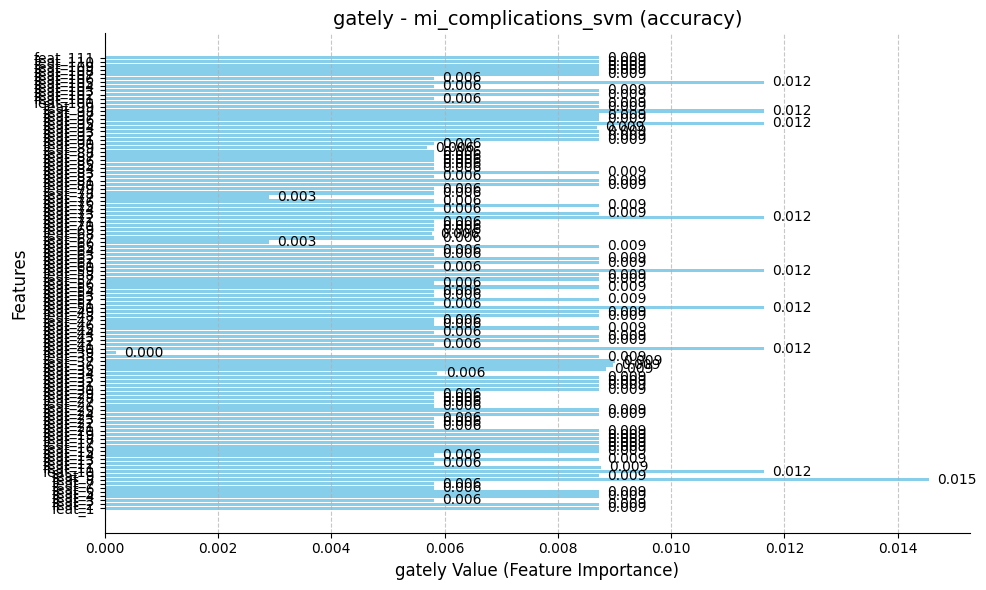

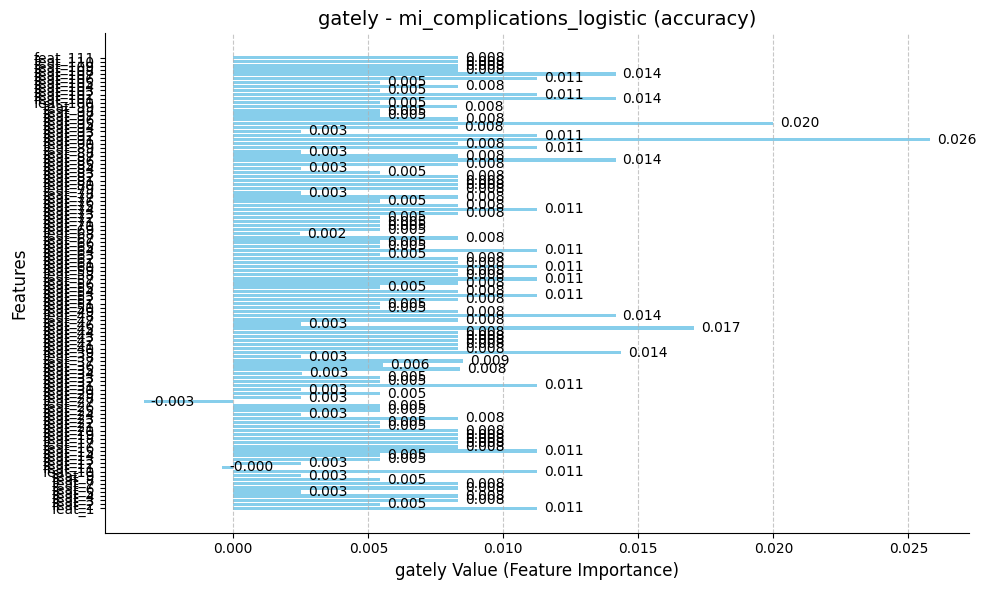

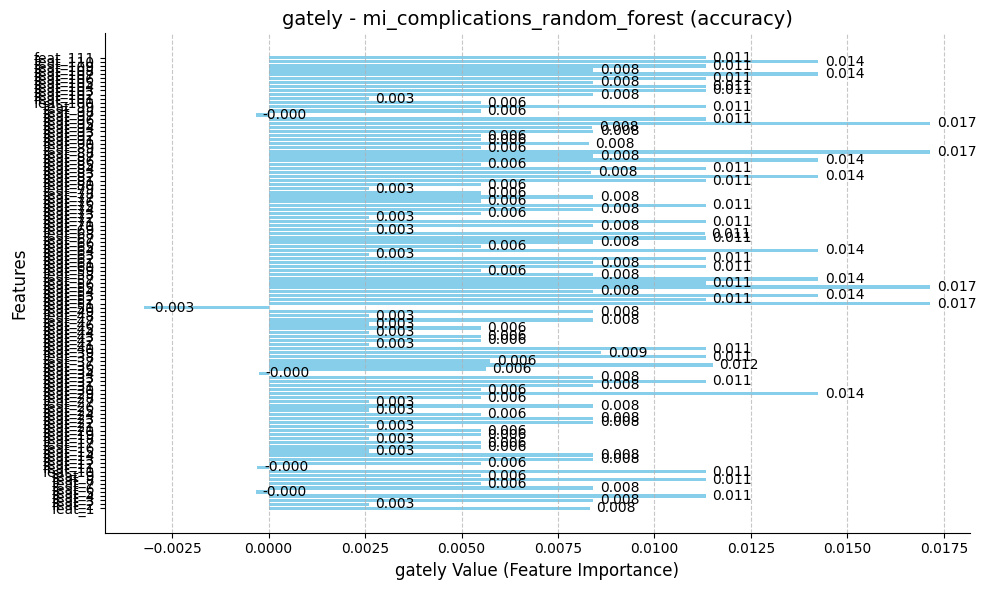

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys
import inspect

# find the repository root
HERE = Path.cwd().resolve()
root = None
for p in [HERE] + list(HERE.parents):
    if (p / "cgt_xai").is_dir():
        root = p
        break
if root is None:
    raise RuntimeError(
        f"Could not find project root from {HERE}. "
        f"Run it from inside the repository."
    )
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
print("Project root added:", root)

from scipy.stats import spearmanr, pearsonr
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, mean_squared_error,
    r2_score, mean_absolute_error
)

# Attribution methods
from cgt_xai.concepts.gately_point import exact_gately_value
from cgt_xai.concepts.shapley import montecarlo_shapley_value
from cgt_xai.concepts.least_core import montecarlo_least_core

from cgt_xai.models import get_model
from cgt_xai.utils.plotting import plot_single_valuation

# Logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config
DATASETS = ["mi_complications"]  # add "lung_cancer" if needed
MODEL_NAMES = ["svm", "logistic", "random_forest"]  # must match get_model()
SCORING = "accuracy"
RANDOM_STATE = 42

# MC settings for Shapley/Least-core
MC_ITERATIONS = 500

BASE_OUTPUT_DIR = Path("./output/feature_valuation_uci")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset loaders
def load_lung_cancer():
    path = "../../../datasets/lung-cancer.data"
    df = pd.read_csv(path, header=None, na_values="?")

    y = df.iloc[:, 0].astype(int).values
    X_df = df.iloc[:, 1:]
    feature_names = [f"attr_{i}" for i in range(1, X_df.shape[1] + 1)]

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_mi_complications(binary_let_is=True):
    path = "../../../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    let_is = df.iloc[:, 123].astype(int).values
    y = (let_is != 0).astype(int) if binary_let_is else let_is

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "lung_cancer":
        return load_lung_cancer()
    elif name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    else:
        raise ValueError(f"Unknown dataset name: {name}")

# Utility + scorer
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)

    def __iter__(self):
        return iter(self.indices)


class Utility:
    """v(S): train model on subset S, evaluate on test."""
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer,
                 feature_names=None, random_state=42):
        self.X_train = np.asarray(X_train)
        self.y_train = np.asarray(y_train)
        self.X_test = np.asarray(X_test)
        self.y_test = np.asarray(y_test)
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(self.X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]

        if len(key) == 0:
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = float(score)
            return float(score)

        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = float(score)
        return float(score)


def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")

# Attribution wrappers (Gately / MC Shapley / Least-Core MC)
_SHAPLEY_SIG = inspect.signature(montecarlo_shapley_value)
_LEASTCORE_SIG = inspect.signature(montecarlo_least_core)

def gately_attribution(utility: Utility) -> np.ndarray:
    res = exact_gately_value(utility, options=None, progress=False)
    return np.asarray(res.values, dtype=float)

def mc_shapley_attribution(utility: Utility, n_iterations: int = 500) -> np.ndarray:
    np.random.seed(utility.random_state)
    sig = _SHAPLEY_SIG
    try:
        if "random_state" in sig.parameters:
            res = montecarlo_shapley_value(
                utility, n_iterations=n_iterations,
                random_state=utility.random_state,
                progress=False
            )
        else:
            res = montecarlo_shapley_value(
                utility, n_iterations=n_iterations,
                options={"random_state": utility.random_state},
                progress=False
            )
    except (TypeError, KeyError):
        res = montecarlo_shapley_value(
            utility, n_iterations=n_iterations, options=None, progress=False
        )
    return np.asarray(res.values, dtype=float)

def least_core_attribution(utility: Utility, n_iterations: int = 500) -> np.ndarray:
    """
    Least-core MC can fail with SCS on some sampled constraint sets.
    We don't change gt_concepts/least_core.py, but we:
      - try SCS with strict options,
      - if it fails: retry with milder options,
      - if still fails: raise to outer try/except and record NaNs.
    """
    np.random.seed(utility.random_state)
    sig = _LEASTCORE_SIG

    try:
        if "random_state" in sig.parameters:
            res = montecarlo_least_core(
                utility,
                n_iterations=n_iterations,
                epsilon=1e-6,
                random_state=utility.random_state,
                options={"solver": "SCS", "max_iters": 25000, "eps": 1e-6, "verbose": False},
                progress=False
            )
        else:
            res = montecarlo_least_core(
                utility,
                n_iterations=n_iterations,
                epsilon=1e-6,
                options={"solver": "SCS", "max_iters": 25000, "eps": 1e-6, "verbose": False,
                         "random_state": utility.random_state},
                progress=False
            )
        return np.asarray(res.values, dtype=float)
    except Exception as e1:
        logger.warning(f"[least_core_mc] SCS attempt-1 failed: {type(e1).__name__}: {e1}")

    # Attempt 2: milder SCS settings (often avoids "Error parsing inputs")
    try:
        # Keep it simple and reduce constraints difficulty.
        if "random_state" in sig.parameters:
            res = montecarlo_least_core(
                utility,
                n_iterations=max(50, n_iterations // 2),
                epsilon=1e-5,
                random_state=utility.random_state,
                options={"solver": "SCS", "max_iters": 50000, "eps": 1e-4, "verbose": False},
                progress=False
            )
        else:
            res = montecarlo_least_core(
                utility,
                n_iterations=max(50, n_iterations // 2),
                epsilon=1e-5,
                options={"solver": "SCS", "max_iters": 50000, "eps": 1e-4, "verbose": False,
                         "random_state": utility.random_state},
                progress=False
            )
        return np.asarray(res.values, dtype=float)
    except Exception as e2:
        logger.warning(f"[least_core_mc] SCS attempt-2 failed: {type(e2).__name__}: {e2}")
        raise

# 4 Metrics: MC, ROAD, IROF(sufficiency), RRS
#   - np.trapz -> np.trapezoid
#   - IROF curve_norm clipped to [0,1]
#   - ROAD uses *mild* OOD by default (permute only a fraction of columns)
def _predict_continuous(model, X):
    if hasattr(model, "predict_proba"):
        proba = np.asarray(model.predict_proba(X))
        if proba.ndim == 2 and proba.shape[1] >= 2:
            return proba[:, 1].astype(float)
        return proba.reshape(-1).astype(float)
    if hasattr(model, "decision_function"):
        z = model.decision_function(X)
        return np.asarray(z).reshape(-1).astype(float)
    return np.asarray(model.predict(X)).reshape(-1).astype(float)

def _baseline_fill_values(X_train):
    return np.mean(X_train, axis=0)

def _replace_feature_with_baseline(X, j, baseline_vals):
    Xr = X.copy()
    Xr[:, j] = baseline_vals[j]
    return Xr

def _make_ood(X_ref, rng, frac=0.15):
    """
    Mild OOD: permute only a fraction of columns.
    Full-column permutation is often too destructive and makes ROAD noisy.
    """
    X_ood = X_ref.copy()
    p = X_ood.shape[1]
    k = max(1, int(frac * p))
    cols = rng.choice(p, size=k, replace=False)
    for j in cols:
        X_ood[:, j] = rng.permutation(X_ood[:, j])
    return X_ood

def metric_MC(phi_vec, model, X_test, baseline_vals):
    pred_full = _predict_continuous(model, X_test)
    deltas = np.zeros(X_test.shape[1], dtype=float)
    for j in range(X_test.shape[1]):
        X_minus = _replace_feature_with_baseline(X_test, j, baseline_vals)
        pred_minus = _predict_continuous(model, X_minus)
        deltas[j] = float(np.mean(np.abs(pred_full - pred_minus)))
    if np.std(deltas) <= 1e-12:
        return {"MC_pearson": np.nan, "MC_p": np.nan, "MC_note": "zero_variance", "MC_vector": deltas}
    r, p = pearsonr(np.abs(phi_vec), deltas)
    return {"MC_pearson": float(r), "MC_p": float(p), "MC_note": "ok", "MC_vector": deltas}

def metric_ROAD(phi_vec, model, X_test, baseline_vals, seed=42, ood_frac=0.15):
    rng = np.random.default_rng(seed)
    X_ood = _make_ood(X_test, rng, frac=ood_frac)
    fX = _predict_continuous(model, X_test)
    fX_ood = _predict_continuous(model, X_ood)
    road = np.zeros(X_test.shape[1], dtype=float)
    for j in range(X_test.shape[1]):
        X_minus = _replace_feature_with_baseline(X_test, j, baseline_vals)
        X_ood_minus = _replace_feature_with_baseline(X_ood, j, baseline_vals)
        fX_minus = _predict_continuous(model, X_minus)
        fX_ood_minus = _predict_continuous(model, X_ood_minus)
        in_eff = float(np.mean(np.abs(fX - fX_minus)))
        ood_eff = float(np.mean(np.abs(fX_ood - fX_ood_minus)))
        road[j] = in_eff - ood_eff
    if np.std(road) <= 1e-12:
        return {"ROAD_pearson": np.nan, "ROAD_p": np.nan, "ROAD_note": "degenerate_road", "ROAD_vector": road}
    r, p = pearsonr(np.abs(phi_vec), road)
    return {"ROAD_pearson": float(r), "ROAD_p": float(p), "ROAD_note": "ok", "ROAD_vector": road}

def metric_IROF_sufficiency(utility, phi_vec, max_steps=None):
    n = len(phi_vec)
    if max_steps is None:
        max_steps = n
    order = np.argsort(-np.abs(phi_vec))
    steps = min(max_steps, n)

    v0 = float(utility([]))
    v_full = float(utility(list(range(n))))

    curve = [v0]
    S = set()
    for t in range(steps):
        S.add(int(order[t]))
        curve.append(float(utility(list(S))))
    curve = np.asarray(curve, dtype=float)

    denom = (v_full - v0)
    if abs(denom) > 1e-12:
        curve_norm = (curve - v0) / abs(denom)
    else:
        curve_norm = np.zeros_like(curve)

    curve_norm = np.clip(curve_norm, 0.0, 1.0)

    x = np.arange(curve_norm.size, dtype=float)
    auc_denom = max(1, curve_norm.size - 1)
    auc = float(np.trapezoid(curve_norm, x) / auc_denom)

    k = max(1, int(0.1 * n))
    perf_10pct = float(curve[min(k, len(curve) - 1)])

    return {
        "IROF_auc_norm": auc,
        "IROF_perf_10pct": perf_10pct,
        "IROF_steps": int(steps),
        "IROF_v0": v0,
        "IROF_vfull": v_full,
        "IROF_curve": curve,
        "IROF_curve_norm": curve_norm,
    }

def _repr(model, X):
    if hasattr(model, "decision_function"):
        z = np.asarray(model.decision_function(X))
        return z.reshape(z.shape[0], -1).astype(float)
    if hasattr(model, "apply"):
        a = np.asarray(model.apply(X))
        return a.reshape(a.shape[0], -1).astype(float)
    if hasattr(model, "predict_proba"):
        p = np.asarray(model.predict_proba(X))
        return p.reshape(p.shape[0], -1).astype(float)
    y = model.predict(X)
    return np.asarray(y).reshape(-1, 1).astype(float)

def metric_RRS(phi_vec, model, X_test, baseline_vals):
    H_full = _repr(model, X_test)
    deltas = np.zeros(X_test.shape[1], dtype=float)
    for j in range(X_test.shape[1]):
        X_minus = _replace_feature_with_baseline(X_test, j, baseline_vals)
        H_minus = _repr(model, X_minus)
        diff = H_full - H_minus
        deltas[j] = float(np.mean(np.linalg.norm(diff, axis=1)))
    if np.std(deltas) <= 1e-12:
        return {"RRS_pearson": np.nan, "RRS_p": np.nan, "RRS_note": "degenerate_rrs", "RRS_vector": deltas}
    r, p = pearsonr(np.abs(phi_vec), deltas)
    return {"RRS_pearson": float(r), "RRS_p": float(p), "RRS_note": "ok", "RRS_vector": deltas}

def compute_4_metrics(phi_vec, trained_model, utility_obj, X_train, X_test, seed=42):
    baseline_vals = _baseline_fill_values(X_train)
    out = {}
    out.update(metric_MC(phi_vec, trained_model, X_test, baseline_vals))
    out.update(metric_ROAD(phi_vec, trained_model, X_test, baseline_vals, seed=seed + 777, ood_frac=0.1))
    out.update(metric_IROF_sufficiency(utility_obj, phi_vec))
    out.update(metric_RRS(phi_vec, trained_model, X_test, baseline_vals))
    return out

# Main
def main():
    scorer = get_scorer(SCORING)

    attribution_methods = {
        "gately": ("exact", gately_attribution)
    }

    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)
        n_features = X_train.shape[1]
        all_features_set = set(range(n_features))

        for model_name in MODEL_NAMES:
            logger.info("\n" + "=" * 70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("=" * 70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            # Train one "full" model for MC/ROAD/RRS
            trained_model = get_model(model_name, RANDOM_STATE)
            trained_model.fit(X_train, y_train)

            # Utility for subset retraining v(S)
            utility = Utility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            v_N = utility(list(all_features_set))
            logger.info(f"  v(N) with all features ({SCORING}) = {v_N:.4f}")

            results = {}
            summary_rows = []

            for method_name, (kind, attrib_fn) in attribution_methods.items():
                logger.info("\n" + "-" * 70)
                logger.info(f"Attribution method: {method_name}")
                logger.info("-" * 70)

                # Compute attribution with failure isolation (esp. least-core)
                phi = None
                err_msg = ""
                try:
                    if kind == "mc":
                        phi = attrib_fn(utility, n_iterations=MC_ITERATIONS)
                    else:
                        phi = attrib_fn(utility)
                    phi = np.asarray(phi, dtype=float)
                    results[method_name] = phi
                except Exception as e:
                    err_msg = f"{type(e).__name__}: {e}"
                    logger.warning(f"  Error: Attribution failed for {method_name}: {err_msg}")
                    phi = np.full(n_features, np.nan, dtype=float)
                    results[method_name] = phi

                # Save valuations even if NaNs (debugging convenience)
                df_vals = pd.DataFrame({"method": method_name, "feature": feature_names, "value": phi})
                vals_csv_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_{method_name}.csv"
                df_vals.to_csv(vals_csv_path, index=False)
                logger.info(f"  Saved valuations to: {vals_csv_path}")

                if np.isfinite(phi).any():
                    try:
                        plot_single_valuation(
                            phi, feature_names,
                            method_name=method_name,
                            title=f"{method_name} - {dataset_name}_{model_name} ({SCORING})",
                            output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_{method_name}.png"
                        )
                    except Exception as e:
                        logger.warning(f"  Could not plot {method_name}: {e}")

                # If attribution failed, write a summary row with NaNs
                if not np.isfinite(phi).all():
                    summary_rows.append({
                        "dataset": dataset_name,
                        "model": model_name,
                        "method": method_name,
                        "attribution_error": err_msg,

                        "MC_pearson": np.nan, "MC_p": np.nan,
                        "ROAD_pearson": np.nan, "ROAD_p": np.nan,
                        "IROF_auc_norm": np.nan, "IROF_perf_10pct": np.nan,
                        "IROF_v0": np.nan, "IROF_vfull": np.nan,
                        "RRS_pearson": np.nan, "RRS_p": np.nan,
                    })
                    continue

                # Compute 4 metrics
                m = compute_4_metrics(phi, trained_model, utility, X_train, X_test, seed=RANDOM_STATE)

                # Save per-feature vectors
                per_feat_df = pd.DataFrame({
                    "feature": feature_names,
                    "phi": phi,
                    "MC_delta_pred_i": m.get("MC_vector", np.full(n_features, np.nan)),
                    "ROAD_i": m.get("ROAD_vector", np.full(n_features, np.nan)),
                    "RRS_i": m.get("RRS_vector", np.full(n_features, np.nan)),
                })
                per_feat_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_per_feature_MC_ROAD_RRS_{method_name}.csv"
                per_feat_df.to_csv(per_feat_csv, index=False)
                logger.info(f"  Saved per-feature MC/ROAD/RRS to: {per_feat_csv}")

                # Save IROF curve
                irof_curve_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_IROF_curve_{method_name}.csv"
                pd.DataFrame({
                    "k_added": np.arange(len(m["IROF_curve"])),
                    "score": m["IROF_curve"],
                    "score_norm": m["IROF_curve_norm"],
                }).to_csv(irof_curve_csv, index=False)

                summary_rows.append({
                    "dataset": dataset_name,
                    "model": model_name,
                    "method": method_name,
                    "attribution_error": "",

                    "MC_pearson": m["MC_pearson"],
                    "MC_p": m["MC_p"],
                    "MC_note": m["MC_note"],

                    "ROAD_pearson": m["ROAD_pearson"],
                    "ROAD_p": m["ROAD_p"],
                    "ROAD_note": m["ROAD_note"],

                    "IROF_auc_norm": m["IROF_auc_norm"],
                    "IROF_perf_10pct": m["IROF_perf_10pct"],
                    "IROF_v0": m["IROF_v0"],
                    "IROF_vfull": m["IROF_vfull"],

                    "RRS_pearson": m["RRS_pearson"],
                    "RRS_p": m["RRS_p"],
                    "RRS_note": m["RRS_note"],
                })

                logger.info(
                    f"  Metrics({method_name}): "
                    f"MC r={m['MC_pearson']:.4f}, ROAD r={m['ROAD_pearson']:.4f}, "
                    f"IROF AUC={m['IROF_auc_norm']:.4f}, RRS r={m['RRS_pearson']:.4f}"
                )

            logger.info("\nCalculating Global Sensitivity (Leave-One-Out Impact)...")
            global_impacts = []
            for i in range(n_features):
                v_N_minus_i = utility(list(all_features_set - {i}))
                global_impacts.append(v_N - v_N_minus_i)
            global_impact_vector = np.asarray(global_impacts, dtype=float)

            sens_rows = []
            for method_name, phi in results.items():
                if not np.isfinite(phi).all():
                    sens_rows.append({
                        "method": method_name,
                        "sensitivity_spearman_absphi": np.nan,
                        "p_value_spearman_absphi": np.nan,
                        "sensitivity_pearson_absphi": np.nan,
                        "p_value_pearson_absphi": np.nan,
                        "cosine_similarity_abs": np.nan,
                    })
                    continue

                # Use |phi| for faithfulness-alignment style metrics
                corr_spearman, p_spearman = spearmanr(np.abs(phi), global_impact_vector)
                corr_pearson, p_pearson = pearsonr(np.abs(phi), global_impact_vector)

                phi_abs = np.abs(phi)
                imp_abs = np.abs(global_impact_vector)
                cos_sim = float(np.dot(phi_abs, imp_abs) / (
                    (np.linalg.norm(phi_abs) * np.linalg.norm(imp_abs)) + 1e-10
                ))

                sens_rows.append({
                    "method": method_name,
                    "sensitivity_spearman_absphi": corr_spearman,
                    "p_value_spearman_absphi": p_spearman,
                    "sensitivity_pearson_absphi": corr_pearson,
                    "p_value_pearson_absphi": p_pearson,
                    "cosine_similarity_abs": cos_sim
                })

                logger.info(
                    f"  {method_name}: "
                    f"Spearman(|phi|,LOO)={corr_spearman:.4f}, "
                    f"Pearson(|phi|,LOO)={corr_pearson:.4f}, "
                    f"AbsCos={cos_sim:.4f}"
                )

            sensitivity_df = pd.DataFrame(sens_rows)
            sens_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_sensitivity_all_methods.csv"
            sensitivity_df.to_csv(sens_csv, index=False)
            logger.info(f"  Saved global sensitivity to: {sens_csv}")

            logger.info("\nEvaluating robustness under input noise...")
            noise_level = 0.05
            noise = np.random.normal(0, noise_level * X_train.std(axis=0), X_train.shape)
            X_train_noisy = X_train + noise

            utility_noisy = Utility(
                X_train_noisy, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            robustness_rows = []
            for method_name, (kind, attrib_fn) in attribution_methods.items():
                phi_original = results[method_name]
                if not np.isfinite(phi_original).all():
                    robustness_rows.append({
                        "method": method_name,
                        "cosine_similarity_abs": np.nan,
                        "rank_correlation": np.nan,
                        "normalized_l2_distance": np.nan
                    })
                    continue

                try:
                    if kind == "mc":
                        phi_noisy = attrib_fn(utility_noisy, n_iterations=MC_ITERATIONS)
                    else:
                        phi_noisy = attrib_fn(utility_noisy)
                    phi_noisy = np.asarray(phi_noisy, dtype=float)
                except Exception as e:
                    logger.warning(f"  Error: Robustness attribution failed for {method_name}: {type(e).__name__}: {e}")
                    robustness_rows.append({
                        "method": method_name,
                        "cosine_similarity_abs": np.nan,
                        "rank_correlation": np.nan,
                        "normalized_l2_distance": np.nan
                    })
                    continue

                # Robustness: magnitude cosine
                o_abs = np.abs(phi_original)
                n_abs = np.abs(phi_noisy)
                cos_sim = float(np.dot(o_abs, n_abs) / (
                    (np.linalg.norm(o_abs) * np.linalg.norm(n_abs)) + 1e-10
                ))

                l2_dist = np.linalg.norm(phi_original - phi_noisy)
                l2_norm = l2_dist / (np.linalg.norm(phi_original) + 1e-10)
                rank_corr, _ = spearmanr(phi_original, phi_noisy)

                robustness_rows.append({
                    "method": method_name,
                    "cosine_similarity_abs": cos_sim,
                    "rank_correlation": rank_corr,
                    "normalized_l2_distance": l2_norm
                })

                logger.info(
                    f"  {method_name}: AbsCos={cos_sim:.4f}, "
                    f"RankCorr={rank_corr:.4f}, L2={l2_norm:.4f}"
                )

            robustness_df = pd.DataFrame(robustness_rows)
            rob_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_robustness_all_methods.csv"
            robustness_df.to_csv(rob_csv, index=False)
            logger.info(f"  Saved global robustness to: {rob_csv}")

            summary_df = pd.DataFrame(summary_rows)
            metrics_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_MC_ROAD_IROF_RRS_summary.csv"
            summary_df.to_csv(metrics_csv, index=False)
            logger.info(f"  Saved 4-metric summary to: {metrics_csv}")

            fig, axes = plt.subplots(1, 3, figsize=(18, 6))

            ax1 = axes[0]
            ax1.barh(sensitivity_df["method"], sensitivity_df["sensitivity_spearman_absphi"])
            ax1.set_xlabel("Spearman(|phi|, LOO)")
            ax1.set_title("Global Sensitivity\n(|Attribution| ↔ LOO Impact)")
            ax1.axvline(0, color="red", linestyle="--", linewidth=1)
            ax1.grid(axis="x", alpha=0.3)

            ax2 = axes[1]
            ax2.barh(sensitivity_df["method"], sensitivity_df["cosine_similarity_abs"])
            ax2.set_xlabel("Abs Cosine Similarity")
            ax2.set_title("Magnitude Alignment\n(|phi| vs |LOO|)")
            ax2.axvline(1.0, color="green", linestyle="--", linewidth=1)
            ax2.grid(axis="x", alpha=0.3)

            ax3 = axes[2]
            ax3.barh(robustness_df["method"], robustness_df["cosine_similarity_abs"])
            ax3.set_xlabel("Abs Cosine (Original ↔ Noisy)")
            ax3.set_title("Global Robustness\n(Magnitude Stability)")
            ax3.axvline(1.0, color="green", linestyle="--", linewidth=1)
            ax3.grid(axis="x", alpha=0.3)

            plt.tight_layout()
            fig_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_faithfulness_all_methods.png"
            plt.savefig(fig_path, dpi=300, bbox_inches="tight")
            plt.close(fig)

            logger.info(f"\nAll results saved to: {OUTPUT_DIR}")
            logger.info("=" * 70)

if __name__ == "__main__":
    main()